In [1]:
import rdkit
import pandas as pd
from validation import *
from rdkit.Chem import Descriptors, Crippen, Lipinski
from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem
import numpy as np
import seaborn
import umap
import matplotlib.pyplot as plt
import seaborn as sns

I0000 00:00:1784824594.440528 1641541 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import plotly
import ipywidgets

In [71]:
df_task1 = pd.read_csv('raw_data_task1.csv')
df_task1


,quantization,model,tokens_per_second,duration_min
0,BF16,gpt-oss-120B,14.255372,8.306117
1,BF16,gpt-oss-120B,14.344542,6.297450
2,BF16,gpt-oss-120B,14.392826,3.095300
3,BF16,gpt-oss-120B,14.016174,13.825083
4,BF16,gpt-oss-120B,13.866866,11.298450
...,...,...,...,...
395,BF16,Mistral4-119B,4.576826,22.101167
396,BF16,Mistral4-119B,4.576121,21.860533
397,BF16,Mistral4-119B,4.598729,4.447450
398,BF16,Mistral4-119B,4.597749,6.884150


In [ ]:
df_task1.groupby(['']).ave

<bound method GroupBy.mean of <pandas.api.typing.DataFrameGroupBy object at 0x7f7c0ecb4050>>

In [3]:
lst_quants = ['BF16', 'Q8', 'Q6', 'Q4']
lst_models = ['Mistral4-119B', 'Qwen3.6-35B', 'gemma-4-31B', 'gpt-oss-120B']
lst_replicas = range(1,20+1)

# Funções

In [4]:
def n_lipinski_violations(smiles_list, threshold=1):
    n_smi_viol = 0
    n_violations = 0
    for smi in smiles_list:
        mol = Chem.MolFromSmiles(smi)
        violations = sum([
            Descriptors.MolWt(mol) > 500,
            Crippen.MolLogP(mol) > 5,
            Lipinski.NumHDonors(mol) > 5,
            Lipinski.NumHAcceptors(mol) > 10
        ])
        n_violations += violations

        if violations > threshold:
            n_smi_viol+=1
    return n_violations, n_smi_viol

In [5]:
def calculate_intdiv(smiles_list):
    lst_mol = [Chem.MolFromSmiles(smi) for smi in smiles_list]
    lst_fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]
    total = len(lst_mol)

    # Tanimoto Similarity for all unique pairs
    lst_sim = []
    
    for i in range(total):
        for j in range(i + 1, total):
            sim = DataStructs.TanimotoSimilarity(lst_fps[i], lst_fps[j])
            lst_sim.append(sim)
            
    # 3. Diversidade = 1 - Média das Similaridades
    avg_sim = sum(lst_sim) / len(lst_sim)
    int_div = 1.0 - avg_sim
    
    return int_div

In [6]:
def get_all_smiles(path='../csv_llms_task_2'):
    d = {}
    for m in lst_models:
        d[m] = {}

        for q in lst_quants:
            d[m][q] = []

            for r in lst_replicas:
                lst_smi = pd.read_csv(f'{path}/{m}-{q}_replica_{r}.csv')['SMILES'].values.tolist()
                lst_valid_smi = validate_smiles(lst_smi)
                d[m][q] += lst_valid_smi
    return d

In [7]:
def calc_umap(d_smiles, q, n_neighbors=15):

    reducer = umap.UMAP(
        n_neighbors=n_neighbors,    # Ajuste este valor (ex: 5 a 30). Como você tem poucas moléculas (69), um valor menor (ex: 5 ou 10) pode revelar mais estrutura local.
        min_dist=0.1,      # Controla o quão agrupados os pontos ficam no gráfico
        metric='jaccard',  # Ideal para fingerprints binários
        random_state=42    # Para reprodutibilidade
    )


    lst_smiles = lst_smiles_prompt.copy()
    for model in lst_models:
        lst_smiles += d_smiles[model][q]
        
    print(len(lst_smiles))

    lst_mols = [Chem.MolFromSmiles(m) for m in lst_smiles if m]
    lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mols]

    embedding = reducer.fit_transform(lst_fps)


    i=0
    lst_index  = ['prompt']*69
    i+=1
    for m in lst_models:
        lst_index += [m]*len(d_smiles[m][q])
        i+=1


    df = pd.DataFrame(embedding, columns=['UMAP_1', 'UMAP_2'])
    df['model'] = lst_index

    return df

In [8]:
def distance(x0,y0,x1,y1):
    return float(np.sqrt( np.power((x0-x1),2)+np.power((y0-y1),2) ))



In [9]:

def calc_dists(df_umap):
    coords_ref = df_umap.loc[df_umap['model']=='prompt'][['UMAP_1','UMAP_2']].values.tolist()

    d_dist = {}

    for model in lst_models:
        d_dist[model] = {}
        d_dist[model]['all'] = []
        d_dist[model]['avg'] = []
        d_dist[model]['min'] = []

        # Get its coordinates
        coords_model = df_umap.loc[df_umap['model']==model][['UMAP_1','UMAP_2']].values.tolist()

        # For each molecule generated by each model...
        for x1,y1 in coords_model:
            lst_dist_mol = []
            for x0,y0 in coords_ref:
                # Distance between each molecule from the model and from the prompt
                d = float(distance(x0,y0,x1,y1))
                lst_dist_mol.append(d)

            # model-promt distances
            d_dist[model]['all'] += lst_dist_mol
            d_dist[model]['avg'].append(float(np.average(np.array(lst_dist_mol))))
            d_dist[model]['min'].append(float(np.min(np.array(lst_dist_mol))))


        #for model in lst_models:
            #print(model, len(d_dist['all'][model]), len(d_dist['min'][model]), len(d_dist['avg'][model]))
    return d_dist

In [28]:
def pairwise_tanimoto_stats(d_smiles):
    d = {}
    
    lst_smi_prompt = d_smiles['prompt']
    lst_mol_prompt = [Chem.MolFromSmiles(smi) for smi in lst_smi_prompt]
    lst_fps_prompt = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol_prompt]
    total_prompt = len(lst_smi_prompt)
    
    for q in lst_quants:
        d[q] = {}
        
        for m in lst_models:
            d[q][m] = {}
            d[q][m]['all'] = []
            d[q][m]['avg'] = []
            d[q][m]['max'] = []
            d[q][m]['med'] = []
            
            
            lst_smi = d_smiles[m][q]
            lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
            lst_fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]
            total = len(lst_smi)
    
    
            for m1 in lst_fps:
                lst_sim = []
                for m2 in lst_fps_prompt:
                    sim = DataStructs.TanimotoSimilarity(m1, m2)
                    lst_sim.append(sim)
                    
                d[q][m]['all'] += lst_sim
                d[q][m]['avg'].append(float(np.average(np.array(lst_sim))))
                d[q][m]['max'].append(float(np.max(np.array(lst_sim))))
                d[q][m]['med'].append(float(np.median(np.array(lst_sim))))
    return d

# Dados das moléculas do prompt

In [10]:
lst_smiles_prompt = pd.read_csv('smiles_prompt.csv')['SMILES'].values.tolist()

n_smi_total = len(lst_smiles_prompt)
lst_valid_smi = validate_smiles(lst_smiles_prompt)
n_smi_valid = len(lst_valid_smi)
n_tot_violations, n_smi_violations = n_lipinski_violations(lst_valid_smi, threshold=1)
intdiv = calculate_intdiv(lst_valid_smi)

d_prompt = {'n_smi_total':n_smi_total, 'n_smi_valid':n_smi_valid,
            'n_tot_violations':n_tot_violations, 'n_smi_violations':n_smi_violations,
            'intdiv':intdiv}

d_prompt['pct_smi_valid'] = d_prompt['n_smi_valid']/d_prompt['n_smi_total']
d_prompt['pct_lipin_viol'] = d_prompt['n_smi_violations']/d_prompt['n_smi_total']

prompt_pct_smi_valid = d_prompt['pct_smi_valid']
prompt_pct_lipin_viol = d_prompt['pct_lipin_viol']
prompt_intdiv = d_prompt['intdiv']

d_prompt

{'n_smi_total': 69,
 'n_smi_valid': 69,
 'n_tot_violations': 24,
 'n_smi_violations': 0,
 'intdiv': 0.8510483566601391,
 'pct_smi_valid': 1.0,
 'pct_lipin_viol': 0.0}

# TASK 1

In [11]:
path = '../csv_llms_task_1'

In [12]:
d = {}
for m in lst_models:
    for q in lst_quants:
        for r in lst_replicas:
            lst_smi = pd.read_csv(f'{path}/{m}-{q}_replica_{r}.csv')['SMILES'].values.tolist()
            n_smi_total = len(lst_smi)
            lst_valid_smi = validate_smiles(lst_smi)
            n_smi_valid = len(lst_valid_smi)
                
            print(f'{m:15s} {q:5s} {r:2.0f} {n_smi_total:2d} {n_smi_valid:2d}')
            d[f'{m}-{q}-{r}'] = { 'm':m, 'q':q, 'r':r, 'n_smi_total':n_smi_total, 'n_smi_valid':n_smi_valid}

Mistral4-119B   BF16   1 20 19
Mistral4-119B   BF16   2 19 15
Mistral4-119B   BF16   3 19 16
Mistral4-119B   BF16   4 19 19
Mistral4-119B   BF16   5 19 19
Mistral4-119B   BF16   6 20 17
Mistral4-119B   BF16   7  0  0
Mistral4-119B   BF16   8 19 15
Mistral4-119B   BF16   9 19 16
Mistral4-119B   BF16  10 20 20
Mistral4-119B   BF16  11 20 17
Mistral4-119B   BF16  12 21 19
Mistral4-119B   BF16  13 20 16
Mistral4-119B   BF16  14 20 19
Mistral4-119B   BF16  15  0  0
Mistral4-119B   BF16  16 20 14
Mistral4-119B   BF16  17 20 16
Mistral4-119B   BF16  18 19 18
Mistral4-119B   BF16  19 20 15
Mistral4-119B   BF16  20 15 12
Mistral4-119B   Q8     1 20 17
Mistral4-119B   Q8     2  0  0
Mistral4-119B   Q8     3 19 19
Mistral4-119B   Q8     4 20 20
Mistral4-119B   Q8     5 22 18
Mistral4-119B   Q8     6 19 16
Mistral4-119B   Q8     7 22 18
Mistral4-119B   Q8     8 20 20
Mistral4-119B   Q8     9 20 20
Mistral4-119B   Q8    10  1  1
Mistral4-119B   Q8    11 20 17
Mistral4-119B   Q8    12 19 19
Mistral4

In [13]:
df = pd.DataFrame.from_dict(d, orient='index')
df['pct_smi_valid'] = df['n_smi_valid']/df['n_smi_total']
df

,m,q,r,n_smi_total,n_smi_valid,pct_smi_valid
Mistral4-119B-BF16-1,Mistral4-119B,BF16,1,20,19,0.950000
Mistral4-119B-BF16-2,Mistral4-119B,BF16,2,19,15,0.789474
Mistral4-119B-BF16-3,Mistral4-119B,BF16,3,19,16,0.842105
Mistral4-119B-BF16-4,Mistral4-119B,BF16,4,19,19,1.000000
Mistral4-119B-BF16-5,Mistral4-119B,BF16,5,19,19,1.000000
...,...,...,...,...,...,...
gpt-oss-120B-Q4-16,gpt-oss-120B,Q4,16,20,19,0.950000
gpt-oss-120B-Q4-17,gpt-oss-120B,Q4,17,20,19,0.950000
gpt-oss-120B-Q4-18,gpt-oss-120B,Q4,18,20,20,1.000000
gpt-oss-120B-Q4-19,gpt-oss-120B,Q4,19,20,20,1.000000


In [14]:
d_stats = {}
for m in lst_models:
    d_stats[m] = {}
    for q in lst_quants:
        d_stats[m][q] = {}
        
        avg = df.loc[(df['m']==m) & (df['q']==q)]['pct_smi_valid'].mean()
        std = df.loc[(df['m']==m) & (df['q']==q)]['pct_smi_valid'].std()
        d_stats[m][q]['pct_smi_valid'] = (float(avg), float(std))
        

---------------------------------------
|        MODEL       | pct_smi_valid  |
---------------------------------------
| Mistral4-119B BF16 | 86.47 +-  9.19 |
| Mistral4-119B Q8   | 90.03 +- 13.92 |
| Mistral4-119B Q6   | 87.72 +-  9.61 |
| Mistral4-119B Q4   | 67.57 +- 29.80 |
|                    |                |
| Qwen3.6-35B   BF16 | 95.59 +-  5.58 |
| Qwen3.6-35B   Q8   | 93.75 +-  6.26 |
| Qwen3.6-35B   Q6   | 97.75 +-  3.80 |
| Qwen3.6-35B   Q4   | 95.00 +-  6.69 |
|                    |                |
| gemma-4-31B   BF16 | 90.25 +-  6.58 |
| gemma-4-31B   Q8   | 87.50 +- 10.70 |
| gemma-4-31B   Q6   | 90.75 +-  6.74 |
| gemma-4-31B   Q4   | 92.75 +-  9.66 |
|                    |                |
| gpt-oss-120B  BF16 | 94.00 +-  5.53 |
| gpt-oss-120B  Q8   | 91.75 +-  8.93 |
| gpt-oss-120B  Q6   | 95.50 +-  4.84 |
| gpt-oss-120B  Q4   | 97.00 +-  2.99 |
|                    |                |
| Prompt             | 100.00         |
----------------------------------------

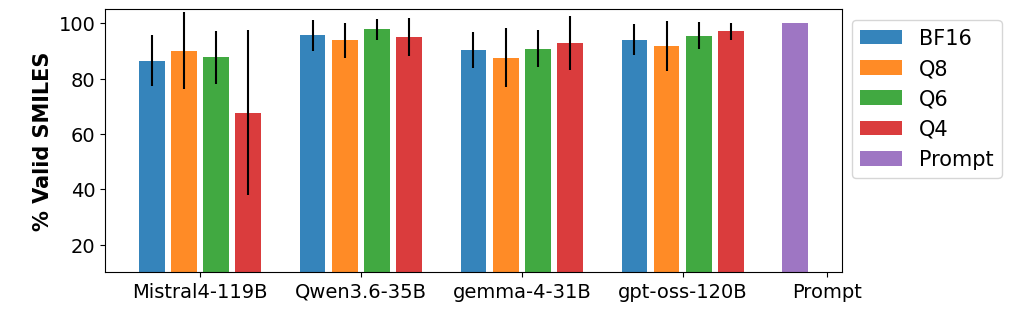

In [15]:
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
alpha=0.90

fig, ax = plt.subplots(1, 1, figsize=(10, 3), constrained_layout=True)
x=0

ax.set_ylabel('\n% Valid SMILES', fontsize=15, fontweight='bold')

print('-'*39)
print(f'|        MODEL       | pct_smi_valid  |')
print('-'*39)

for n_model,m in enumerate(lst_models):
    for n_quant, q in enumerate(lst_quants):
        if n_model==0:
            label=q
        else:
            label=''

        valid_avg, valid_std = d_stats[m][q]['pct_smi_valid']

        ax.bar(x=x, height=valid_avg*100, yerr=valid_std*100, color=default_colors[n_quant], label=label, alpha=alpha)

        x+=1

        
        print(f'| {m:13s} {q:4s} | {valid_avg*100:5.2f} +- {valid_std*100:5.2f} |')
    print(f'|                    |                |')
    x+=1

print(f'| Prompt             | {prompt_pct_smi_valid*100:5.2f}         |')

print('-'*71)

ax.bar(x=x, height=prompt_pct_smi_valid*100,  color=default_colors[n_quant+1], label='Prompt', alpha=alpha)

ax.set_ylim([10,105])

ax.set_xticks([2.5-1, 7.5-1, 12.5-1, 17.5-1, 21])
ax.set_xticklabels(lst_models+['Prompt'], fontsize=14)
ax.legend(bbox_to_anchor=(1.00, 1.00), loc="upper left", fontsize=15)
ax.tick_params(axis='y', labelsize=14)

# TASK 2

In [16]:
path = '..//csv_llms_task_2'

In [17]:
d = {}
for m in lst_models:
    for q in lst_quants:
        for r in lst_replicas:
            lst_smi = pd.read_csv(f'{path}/{m}-{q}_replica_{r}.csv')['SMILES'].values.tolist()
            n_smi_total = len(lst_smi)
            lst_valid_smi = validate_smiles(lst_smi)
            n_smi_valid = len(lst_valid_smi)
            
            if n_smi_valid == 0:
                n_smi_violations = np.nan
                n_tot_violations = np.nan
                intdiv = np.nan
            elif n_smi_valid == 1:
                n_tot_violations, n_smi_violations = n_lipinski_violations(lst_valid_smi, threshold=1)
                
                intdiv = np.nan
            else:
                n_tot_violations, n_smi_violations = n_lipinski_violations(lst_valid_smi, threshold=1)
                intdiv = calculate_intdiv(lst_valid_smi)
                
            print(f'{m:15s} {q:5s} {r:2.0f} {n_smi_total:2d} {n_smi_valid:2d} {n_tot_violations:2.0f} {n_smi_violations:4.0f} {intdiv:5.2f}')
            d[f'{m}-{q}-{r}'] = { 'm':m, 'q':q, 'r':r, 'n_smi_total':n_smi_total, 'n_smi_valid':n_smi_valid,
                                  'n_tot_violations':n_tot_violations, 'n_smi_violations':n_smi_violations,
                                  'intdiv':intdiv}



Mistral4-119B   BF16   1 19  8  4    0  0.75
Mistral4-119B   BF16   2 19  3  0    0  0.83
Mistral4-119B   BF16   3  0  0 nan  nan   nan
Mistral4-119B   BF16   4 19 18  0    0  0.74
Mistral4-119B   BF16   5 19  4  1    0  0.86
Mistral4-119B   BF16   6 20 17  0    0  0.86
Mistral4-119B   BF16   7 19 18  2    0  0.84
Mistral4-119B   BF16   8 19 19  0    0  0.81
Mistral4-119B   BF16   9 19 16  0    0  0.68
Mistral4-119B   BF16  10 19 13  0    0  0.83
Mistral4-119B   BF16  11 19 15  1    0  0.87
Mistral4-119B   BF16  12  0  0 nan  nan   nan
Mistral4-119B   BF16  13 30 17  1    0  0.85
Mistral4-119B   BF16  14 19 15  0    0  0.68
Mistral4-119B   BF16  15 18 17  0    0  0.65
Mistral4-119B   BF16  16 19 16  1    0  0.83
Mistral4-119B   BF16  17 19 12  0    0  0.81
Mistral4-119B   BF16  18 20 15  2    0  0.79
Mistral4-119B   BF16  19 21 17  0    0  0.74
Mistral4-119B   BF16  20 21 21  0    0  0.83
Mistral4-119B   Q8     1 19 15  0    0  0.83
Mistral4-119B   Q8     2  1  1  0    0   nan
Mistral4

In [18]:
df = pd.DataFrame.from_dict(d, orient='index')
df['pct_smi_valid'] = df['n_smi_valid']/df['n_smi_total']
df['pct_lipinski_viol'] = df['n_smi_violations']/df['n_smi_valid']
df['avg_viol_per_smi'] = df['n_tot_violations']/df['n_smi_valid']
df

,m,q,r,n_smi_total,n_smi_valid,n_tot_violations,n_smi_violations,intdiv,pct_smi_valid,pct_lipinski_viol,avg_viol_per_smi
Mistral4-119B-BF16-1,Mistral4-119B,BF16,1,19,8,4.0,0.0,0.751562,0.421053,0.0,0.50
Mistral4-119B-BF16-2,Mistral4-119B,BF16,2,19,3,0.0,0.0,0.827236,0.157895,0.0,0.00
Mistral4-119B-BF16-3,Mistral4-119B,BF16,3,0,0,NaN,NaN,NaN,NaN,NaN,NaN
Mistral4-119B-BF16-4,Mistral4-119B,BF16,4,19,18,0.0,0.0,0.739384,0.947368,0.0,0.00
Mistral4-119B-BF16-5,Mistral4-119B,BF16,5,19,4,1.0,0.0,0.860368,0.210526,0.0,0.25
...,...,...,...,...,...,...,...,...,...,...,...
gpt-oss-120B-Q4-16,gpt-oss-120B,Q4,16,20,15,0.0,0.0,0.681385,0.750000,0.0,0.00
gpt-oss-120B-Q4-17,gpt-oss-120B,Q4,17,20,15,0.0,0.0,0.749012,0.750000,0.0,0.00
gpt-oss-120B-Q4-18,gpt-oss-120B,Q4,18,20,14,0.0,0.0,0.594732,0.700000,0.0,0.00
gpt-oss-120B-Q4-19,gpt-oss-120B,Q4,19,20,19,0.0,0.0,0.824712,0.950000,0.0,0.00


In [19]:
d_stats = {}
for m in lst_models:
    d_stats[m] = {}
    for q in lst_quants:
        d_stats[m][q] = {}
        avg = df.loc[(df['m']==m) & (df['q']==q)]['pct_lipinski_viol'].mean()
        std = df.loc[(df['m']==m) & (df['q']==q)]['pct_lipinski_viol'].std()
        d_stats[m][q]['pct_lipinski_viol'] = (float(avg), float(std))

        avg = df.loc[(df['m']==m) & (df['q']==q)]['intdiv'].mean()
        std = df.loc[(df['m']==m) & (df['q']==q)]['intdiv'].std()
        d_stats[m][q]['intdiv'] = (float(avg), float(std))

        avg = df.loc[(df['m']==m) & (df['q']==q)]['pct_smi_valid'].mean()
        std = df.loc[(df['m']==m) & (df['q']==q)]['pct_smi_valid'].std()
        d_stats[m][q]['pct_smi_valid'] = (float(avg), float(std))

        avg = df.loc[(df['m']==m) & (df['q']==q)]['avg_viol_per_smi'].mean()
        std = df.loc[(df['m']==m) & (df['q']==q)]['avg_viol_per_smi'].std()
        d_stats[m][q]['avg_viol_per_smi'] = (float(avg), float(std))

-----------------------------------------------------------------------
|        MODEL       | pct_smi_valid  | pct_lipin_viol | intdiv       |
-----------------------------------------------------------------------
| Mistral4-119B BF16 | 73.24 +- 25.09 |  0.00 +-  0.00 | 0.79 +- 0.07 | 
| Mistral4-119B Q8   | 67.34 +- 33.06 |  0.00 +-  0.00 | 0.80 +- 0.06 | 
| Mistral4-119B Q6   | 53.29 +- 25.22 |  0.00 +-  0.00 | 0.80 +- 0.04 | 
| Mistral4-119B Q4   | 44.12 +- 30.14 |  0.49 +-  2.02 | 0.82 +- 0.03 | 
|                    |                |                |              |
| Qwen3.6-35B   BF16 | 81.75 +- 14.07 | 10.89 +- 12.79 | 0.74 +- 0.05 | 
| Qwen3.6-35B   Q8   | 82.00 +- 18.17 |  7.30 +- 14.57 | 0.72 +- 0.08 | 
| Qwen3.6-35B   Q6   | 68.25 +- 29.70 |  6.59 +- 12.37 | 0.68 +- 0.11 | 
| Qwen3.6-35B   Q4   | 71.91 +- 23.99 |  6.27 +-  9.70 | 0.68 +- 0.08 | 
|                    |                |                |              |
| gemma-4-31B   BF16 | 92.75 +-  8.96 |  6.87 +-  5.60 |

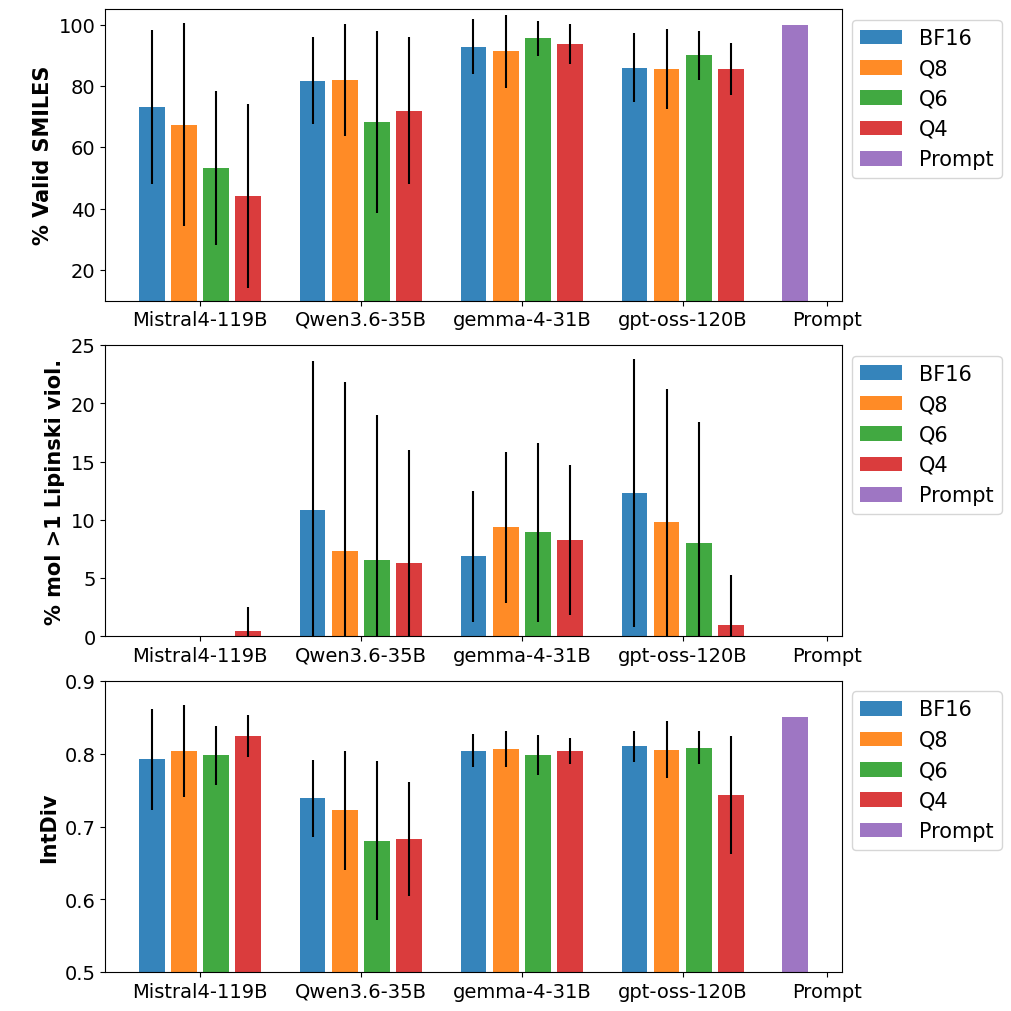

In [20]:
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
alpha = 0.90

fig, ax = plt.subplots(3, 1, figsize=(10, 10), constrained_layout=True)
x=0

#ax[0].set_title('\nvalid', fontsize=15, fontweight='bold')
#ax[1].set_title('\nviol', fontsize=15, fontweight='bold')
#ax[2].set_title('\nintdiv', fontsize=15, fontweight='bold')

ax[0].set_ylabel('\n% Valid SMILES', fontsize=15, fontweight='bold')
ax[1].set_ylabel('\n% mol >1 Lipinski viol.', fontsize=15, fontweight='bold')
ax[2].set_ylabel('\nIntDiv', fontsize=15, fontweight='bold')


print('-'*71)
print(f'|        MODEL       | pct_smi_valid  | pct_lipin_viol | intdiv       |')
print('-'*71)

for n_model,m in enumerate(lst_models):
    for n_quant, q in enumerate(lst_quants):
        if n_model==0:
            label=q
        else:
            label=''

        valid_avg, valid_std = d_stats[m][q]['pct_smi_valid']
        viol_avg, viol_std = d_stats[m][q]['pct_lipinski_viol']
        intdiv_avg, intdiv_std = d_stats[m][q]['intdiv']
        
        ax[0].bar(x=x, height=valid_avg*100, yerr=valid_std*100, color=default_colors[n_quant], label=label, alpha=alpha)
        ax[1].bar(x=x, height=viol_avg*100, yerr=viol_std*100, color=default_colors[n_quant], label=label, alpha=alpha)
        ax[2].bar(x=x, height=intdiv_avg, yerr=intdiv_std, color=default_colors[n_quant], label=label, alpha=alpha)
        
        x+=1
        print(f'| {m:13s} {q:4s} | \
{valid_avg*100:5.2f} +- {valid_std*100:5.2f} | \
{viol_avg*100:5.2f} +- {viol_std*100:5.2f} | \
{intdiv_avg:4.2f} +- {intdiv_std:4.2f} | ')
    
    print(f'|                    |                |                |              |')
    x+=1
        

print(f'| Prompt             | {prompt_pct_smi_valid*100:5.2f}         | {prompt_pct_lipin_viol*100:5.2f}          | {prompt_intdiv:4.2f}         |')      
print('-'*71)

ax[0].bar(x=x, height=prompt_pct_smi_valid*100,  color=default_colors[n_quant+1], label='Prompt', alpha=alpha)
ax[1].bar(x=x, height=prompt_pct_lipin_viol*100, color=default_colors[n_quant+1], label='Prompt', alpha=alpha)
ax[2].bar(x=x, height=prompt_intdiv,             color=default_colors[n_quant+1], label='Prompt', alpha=alpha)

ax[0].set_ylim([10,105])
ax[1].set_ylim([0,25])
ax[2].set_ylim([0.50,0.90])

for i in range(0,3):
    ax[i].set_xticks([2.5-1, 7.5-1, 12.5-1, 17.5-1, 21])
    ax[i].set_xticklabels(lst_models+['Prompt'], fontsize=14)
    ax[i].legend(bbox_to_anchor=(1.00, 1.00), loc="upper left", fontsize=15)
    ax[i].tick_params(axis='y', labelsize=14)


# Chemical Space

In [21]:
d = {}
for m in lst_models:
    d[m] = {}

    for q in lst_quants:
        d[m][q] = []

        for r in lst_replicas:
            lst_smi = pd.read_csv(f'{path}/{m}-{q}_replica_{r}.csv')['SMILES'].values.tolist()
            lst_valid_smi = validate_smiles(lst_smi)
            d[m][q] += lst_valid_smi

/media/data/miniconda3/envs/AIchemist/lib/python3.13/site-packages/umap/umap_.py:1887: UserWarning: gradient function is not yet implemented for jaccard distance metric; inverse_transform will be unavailable
  warn(
/media/data/miniconda3/envs/AIchemist/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/media/data/miniconda3/envs/AIchemist/lib/python3.13/site-packages/numba/np/ufunc/parallel.py:371: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


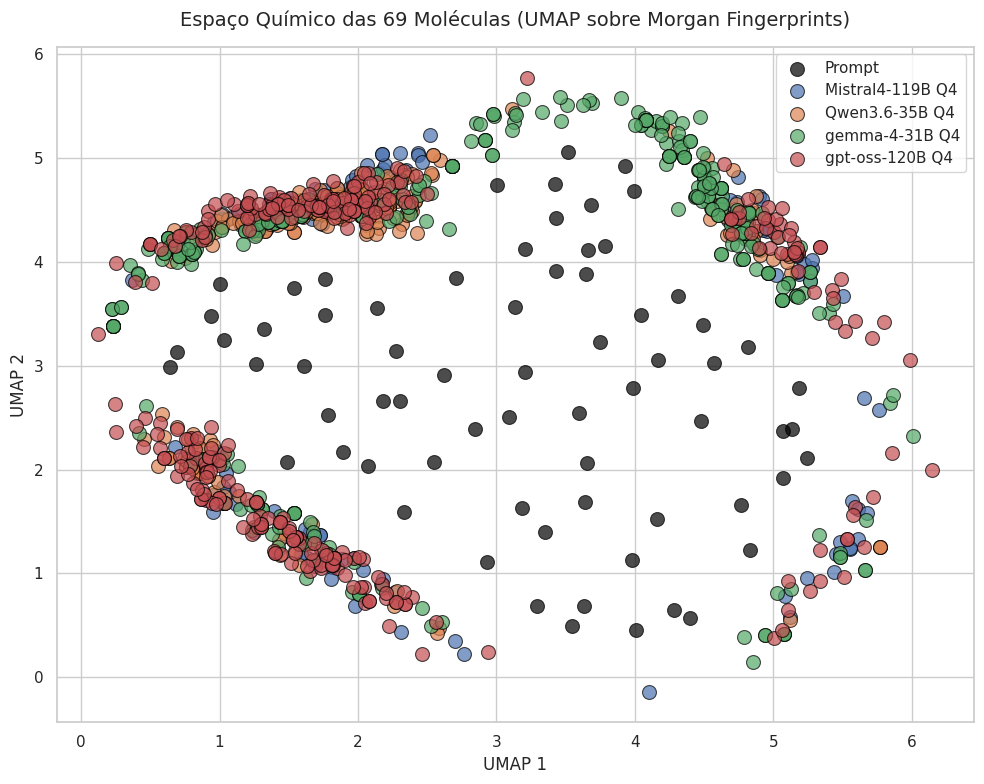

In [22]:
#import pandas as pd
#import numpy as np
#import matplotlib.pyplot as plt
#import seaborn as sns
#from rdkit import Chem
#from rdkit.Chem import AllChem
#import umap

reducer = umap.UMAP(
    n_neighbors=15,    # Ajuste este valor (ex: 5 a 30). Como você tem poucas moléculas (69), um valor menor (ex: 5 ou 10) pode revelar mais estrutura local.
    min_dist=0.1,      # Controla o quão agrupados os pontos ficam no gráfico
    metric='jaccard',  # Ideal para fingerprints binários
    random_state=42    # Para reprodutibilidade
)


lst_mols = [Chem.MolFromSmiles(m) for m in lst_smiles_prompt if m]
lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mols]

embedding_ref = reducer.fit_transform(lst_fps)
df_ref = pd.DataFrame(embedding_ref, columns=['UMAP_1', 'UMAP_2'])

plt.figure(figsize=(10, 8))
sns.set_theme(style="whitegrid")

# Criar o gráfico de dispersão
scatter = sns.scatterplot(data=df_ref, x='UMAP_1', y='UMAP_2', s=100, alpha=0.7, color='black', edgecolor='black', label='Prompt')

# ---------------------------------------------------------------------------

for model in d:
    lst_mols = [Chem.MolFromSmiles(m) for m in d[model]['Q4'] if m]
    lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mols]
    embedding_comp = reducer.transform(lst_fps)
    df_comp = pd.DataFrame(embedding_comp, columns=['UMAP_1', 'UMAP_2'])

    scatter = sns.scatterplot(data=df_comp, x='UMAP_1', y='UMAP_2', s=100, alpha=0.7, edgecolor='black', label=model+' Q4')


# ---------------------------------------------------------------------------




plt.title('Espaço Químico das 69 Moléculas (UMAP sobre Morgan Fingerprints)', fontsize=14, pad=15)
plt.xlabel('UMAP 1', fontsize=12)
plt.ylabel('UMAP 2', fontsize=12)

# (Opcional) Adicionar rótulos em alguns pontos
# Descomente o bloco abaixo se quiser ver os IDs em cima dos pontos
# for i in range(df.shape[0]):
#     plt.text(df['UMAP_1'][i] + 0.1, df['UMAP_2'][i] + 0.1, 
#              df['ID'][i], fontsize=8, alpha=0.7)

plt.tight_layout()
plt.show()

In [23]:
prev_a = 0
prev_b = 69

print('prompt ', prev_a, prev_b)
for m in lst_models:
    l = len(d[m]['Q4'])
    a = prev_b
    b = a + l
    print(l, m, a, b )
    prev_a = a
    prev_b = b

prompt  0 69
142 Mistral4-119B 69 211
289 Qwen3.6-35B 211 500
375 gemma-4-31B 500 875
325 gpt-oss-120B 875 1200


1200


/home/leandro/local/micromamba/envs/jupyter/lib/python3.14/site-packages/umap/umap_.py:1887: UserWarning: gradient function is not yet implemented for jaccard distance metric; inverse_transform will be unavailable
  warn(
/home/leandro/local/micromamba/envs/jupyter/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


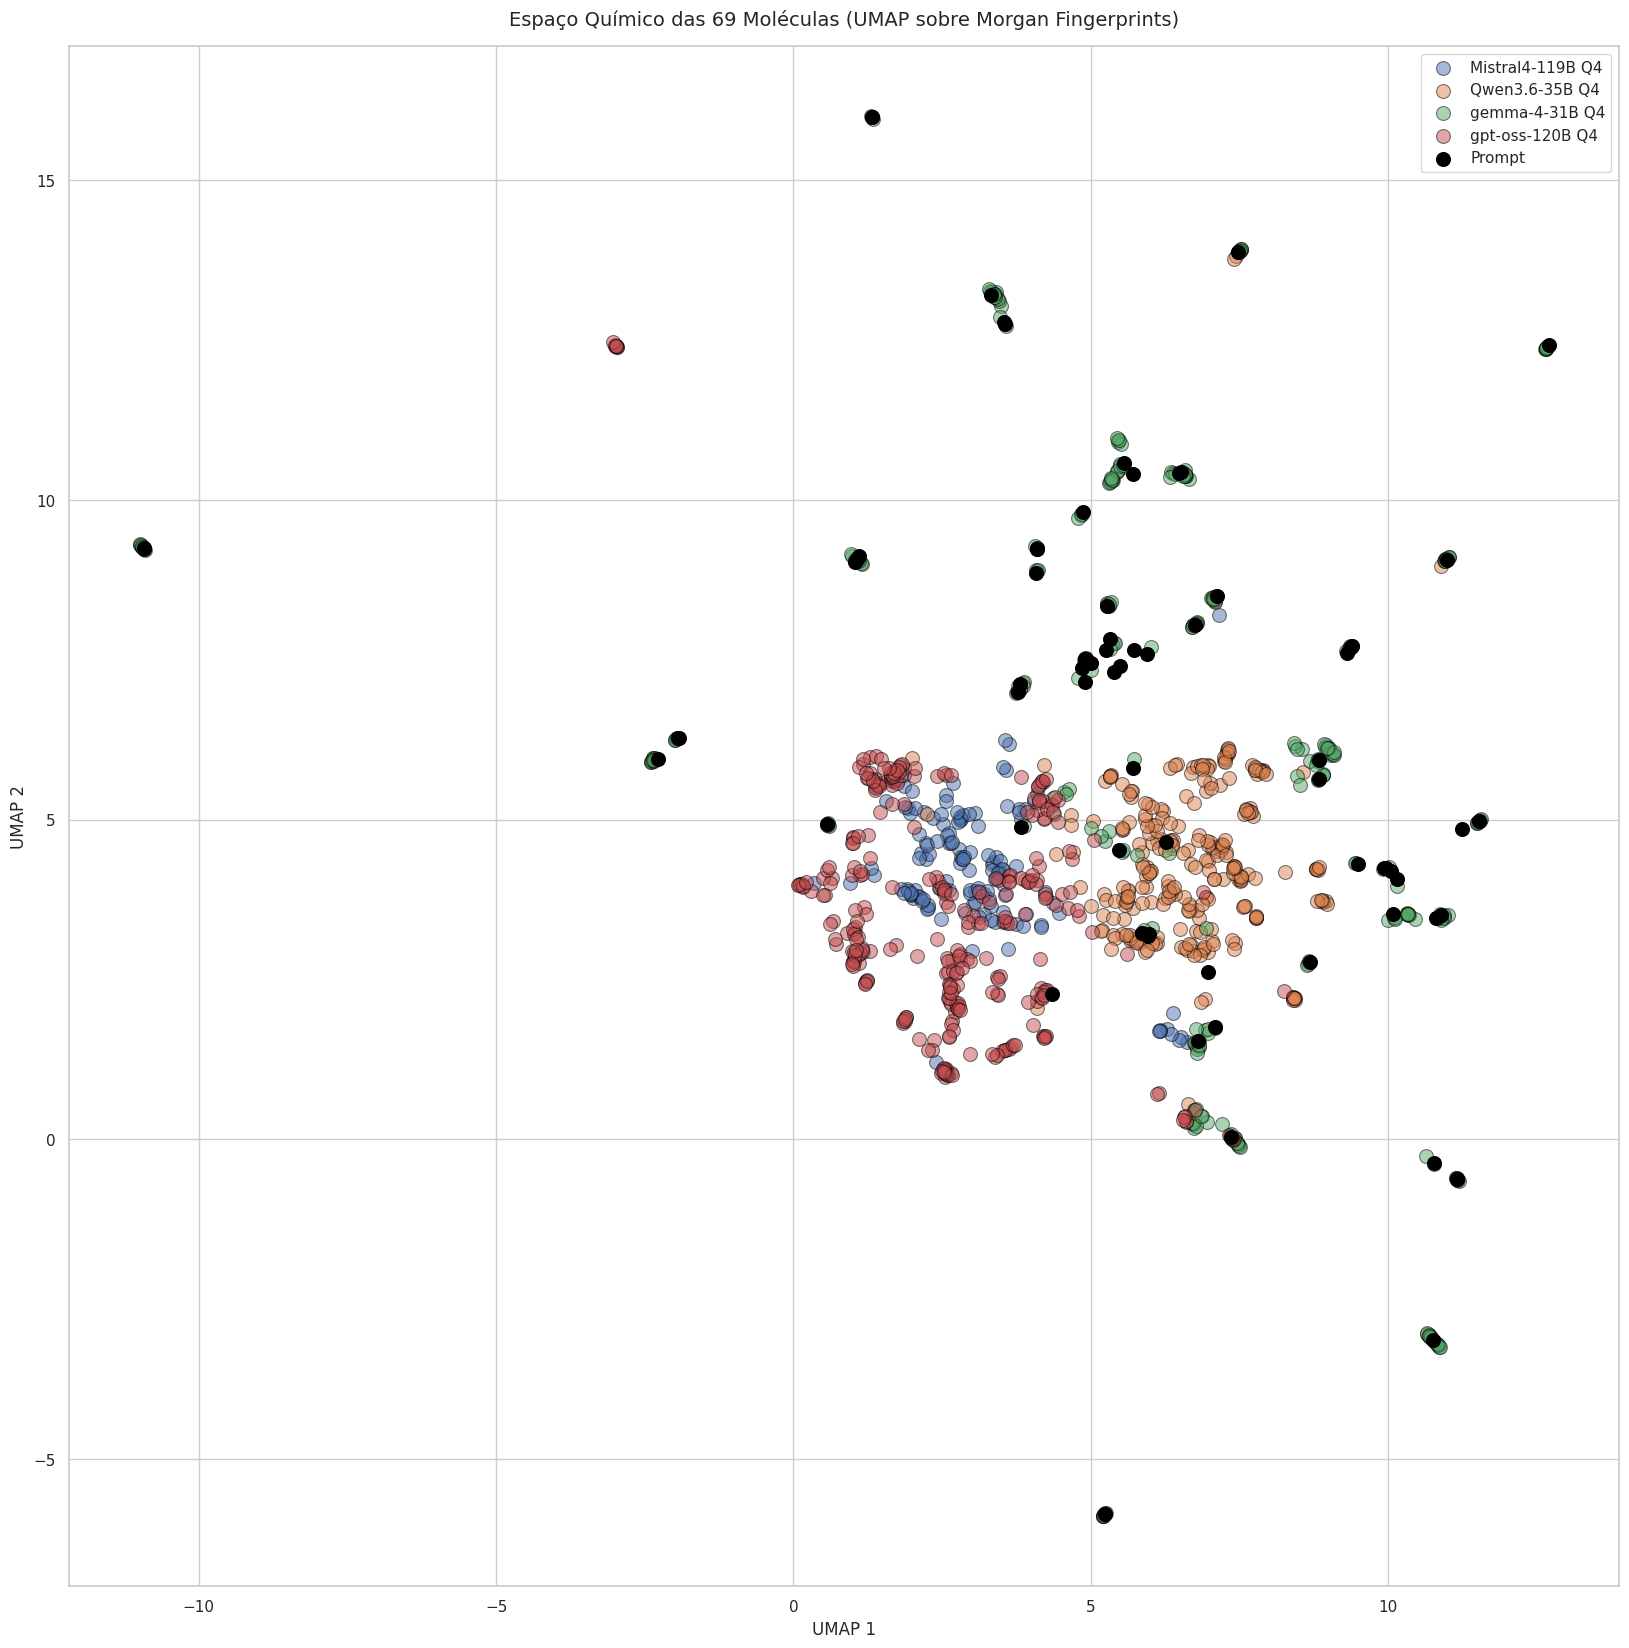

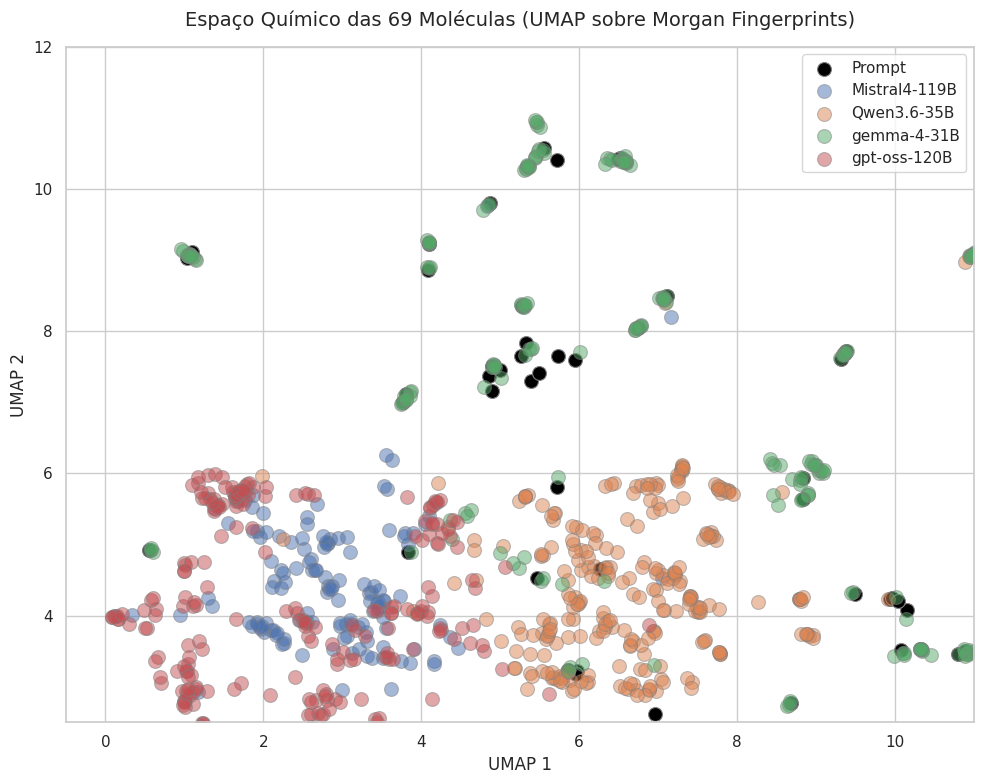

In [24]:
#import pandas as pd
#import numpy as np
#import matplotlib.pyplot as plt
#import seaborn as sns
#from rdkit import Chem
#from rdkit.Chem import AllChem
#import umap

q='Q4'

reducer = umap.UMAP(
    n_neighbors=15,    # Ajuste este valor (ex: 5 a 30). Como você tem poucas moléculas (69), um valor menor (ex: 5 ou 10) pode revelar mais estrutura local.
    min_dist=0.1,      # Controla o quão agrupados os pontos ficam no gráfico
    metric='jaccard',  # Ideal para fingerprints binários
    random_state=42    # Para reprodutibilidade
)
#print(d)


lst_smiles = lst_smiles_prompt.copy()
for model in lst_models:
    lst_smiles += d[model][q]
    
print(len(lst_smiles))

lst_mols = [Chem.MolFromSmiles(m) for m in lst_smiles if m]
lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mols]

embedding = reducer.fit_transform(lst_fps)
df = pd.DataFrame(embedding, columns=['UMAP_1', 'UMAP_2'])

plt.figure(figsize=(20,20))
sns.set_theme(style="whitegrid")

# Criar o gráfico de dispersão

prev_a = 0
prev_b = 69
for m in lst_models:
    l = len(d[m]['Q4'])
    a = prev_b
    b = a + l
    #print(l, m, a, b )
    prev_a = a
    prev_b = b
    scatter = sns.scatterplot(data=df[a:b], x='UMAP_1', y='UMAP_2', s=100, alpha=0.5,  edgecolor='black', label=f'{m} {q}')
scatter = sns.scatterplot(data=df[0:69], x='UMAP_1', y='UMAP_2', s=100, alpha=1.0, color='black', edgecolor='black', label='Prompt')



plt.title('Espaço Químico das 69 Moléculas (UMAP sobre Morgan Fingerprints)', fontsize=14, pad=15)
plt.xlabel('UMAP 1', fontsize=12)
plt.ylabel('UMAP 2', fontsize=12)




plt.figure(figsize=(10, 8))
sns.set_theme(style="whitegrid")

# Criar o gráfico de dispersão
scatter = sns.scatterplot(data=df[0:69], x='UMAP_1', y='UMAP_2', s=100, alpha=1.0, color='black', edgecolor='gray', label='Prompt')

prev_a = 0
prev_b = 69
for m in lst_models:
    l = len(d[m]['Q4'])
    a = prev_b
    b = a + l
    #print(l, m, a, b )
    prev_a = a
    prev_b = b
    scatter = sns.scatterplot(data=df[a:b], x='UMAP_1', y='UMAP_2', s=100, alpha=0.5,  edgecolor='gray', label=m)



plt.title('Espaço Químico das 69 Moléculas (UMAP sobre Morgan Fingerprints)', fontsize=14, pad=15)
plt.ylim([2.5,12])
plt.xlim([-0.5,11])
plt.xlabel('UMAP 1', fontsize=12)
plt.ylabel('UMAP 2', fontsize=12)

# (Opcional) Adicionar rótulos em alguns pontos
# Descomente o bloco abaixo se quiser ver os IDs em cima dos pontos
# for i in range(df.shape[0]):
#     plt.text(df['UMAP_1'][i] + 0.1, df['UMAP_2'][i] + 0.1, 
#              df['ID'][i], fontsize=8, alpha=0.7)

plt.tight_layout()
plt.show()

In [24]:
import pandas as pd
import plotly.graph_objects as go
from rdkit import Chem
from rdkit.Chem import AllChem
import umap
import ipywidgets as widgets
from IPython.display import display

# (Assumindo que lst_smiles_prompt, lst_models e o dicionário 'd' já estão na memória)

# ==========================================
# 1. FUNÇÕES AUXILIARES DE PROCESSAMENTO
# ==========================================
def calcular_dados(q_val, n_vizinhos):
    """Gera a lista unificada de SMILES, calcula os Fingerprints e roda o UMAP."""
    # 1. Reconstruir a lista de SMILES
    smiles_atuais = lst_smiles_prompt.copy()
    for m in lst_models:
        smiles_atuais += d[m][q_val]
        
    # 2. Recalcular Moléculas e Fingerprints
    mols = [Chem.MolFromSmiles(m) for m in smiles_atuais if m]
    fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in mols]
    
    # 3. Rodar UMAP
    reducer = umap.UMAP(n_neighbors=n_vizinhos, min_dist=0.1, metric='jaccard', random_state=42)
    embedding_atual = reducer.fit_transform(fps)
    
    return smiles_atuais, embedding_atual

# ==========================================
# 2. CONFIGURAÇÃO INICIAL
# ==========================================
q_inicial = 'Q4'
n_inicial = 15

# Calcula o estado inicial
smiles_base, embedding_base = calcular_dados(q_inicial, n_inicial)

fig = go.FigureWidget()

# --- TRACE 0: Prompt (Sempre os primeiros 69) ---
fig.add_trace(go.Scatter(
    x=embedding_base[0:69, 0], y=embedding_base[0:69, 1], mode='markers', name='Prompt',
    marker=dict(size=18, color='black', opacity=1.0, line=dict(width=1.5, color='gray')),
    text=[f"<b>ID:</b> Molecule_{i}<br><b>SMILES:</b> {smiles_base[i]}" for i in range(69)],
    hoverinfo="text"
))

# --- TRACES SEGUINTES: Modelos ---
prev_b = 69
for m in lst_models:
    l = len(d[m][q_inicial])
    a = prev_b
    b = a + l
    fig.add_trace(go.Scatter(
        x=embedding_base[a:b, 0], y=embedding_base[a:b, 1], mode='markers', name=f'{m} ({q_inicial})',
        marker=dict(size=10, opacity=1.0, line=dict(width=1, color='white')),
        text=[f"<b>ID:</b> Molecule_{i}<br><b>SMILES:</b> {smiles_base[i]}" for i in range(a, b)],
        hoverinfo="text"
    ))
    prev_b = b

# Layout base do gráfico
fig.update_layout(
    font=dict(size=14),
    title={
        'text': 'Espaço Químico (Ajuste Interativo do UMAP e Quantização)',
        'y': 0.95, 'x': 0.5, 'xanchor': 'center', 'yanchor': 'top',
        'font': dict(size=16, color='#2c3e50')
    },
    plot_bgcolor='white', paper_bgcolor='white', hovermode='closest', width=950, height=750,
    xaxis=dict(title='UMAP 1', gridcolor='#e2e8f0', zerolinecolor='#cbd5e1'),
    yaxis=dict(title='UMAP 2', gridcolor='#e2e8f0', zerolinecolor='#cbd5e1'),
    legend=dict(title="Fontes / Modelos", yanchor="top", y=1, xanchor="left", x=1.02, 
                bgcolor="rgba(255, 255, 255, 0.85)", bordercolor="#cbd5e1", borderwidth=1)
)

# ==========================================
# 3. WIDGETS E CALLBACK DE ATUALIZAÇÃO
# ==========================================
# Menu Dropdown para a variável Q
dropdown_q = widgets.Dropdown(
    options=['BF16', 'Q8', 'Q6', 'Q4'],
    value=q_inicial,
    description='Variável Q:',
    style={'description_width': 'initial'}
)

# Caixa de texto numérico para o n_neighbors
input_neighbors = widgets.BoundedIntText(
    value=n_inicial, min=2, max=200, step=1,
    description='n_neighbors:',
    style={'description_width': 'initial'},
    continuous_update=False 
)

def atualizar_grafico(*args):
    # Pega os valores atuais dos widgets
    q_atual = dropdown_q.value
    n_atual = input_neighbors.value
    
    # Recalcula tudo (Moléculas, Fingerprints e UMAP)
    novos_smiles, novo_embedding = calcular_dados(q_atual, n_atual)
    
    # Atualiza o gráfico de forma silenciosa
    with fig.batch_update():
        # Atualiza o Prompt
        fig.data[0].x = novo_embedding[0:69, 0]
        fig.data[0].y = novo_embedding[0:69, 1]
        
        # Atualiza os modelos subsequentes
        prev_b_loop = 69
        for i, m in enumerate(lst_models):
            l = len(d[m][q_atual])
            a = prev_b_loop
            b = a + l
            
            # Atualiza coordenadas
            fig.data[i+1].x = novo_embedding[a:b, 0]
            fig.data[i+1].y = novo_embedding[a:b, 1]
            # Atualiza o texto do hover (SMILES mudaram)
            fig.data[i+1].text = [f"<b>ID:</b> Molecule_{j}<br><b>SMILES:</b> {novos_smiles[j]}" for j in range(a, b)]
            # Atualiza o nome da legenda para refletir o 'q' atual
            fig.data[i+1].name = f'{m} ({q_atual})'
            
            prev_b_loop = b

# Conecta os widgets à função de atualização
dropdown_q.observe(atualizar_grafico, names='value')
input_neighbors.observe(atualizar_grafico, names='value')

# ==========================================
# 4. EXIBIR TUDO NA TELA
# ==========================================
# Organiza os controles lado a lado (HBox) acima do gráfico
painel_controles = widgets.HBox([dropdown_q, input_neighbors])
display(widgets.VBox([painel_controles, fig]))

/media/data/miniconda3/envs/AIchemist/lib/python3.13/site-packages/umap/umap_.py:1887: UserWarning: gradient function is not yet implemented for jaccard distance metric; inverse_transform will be unavailable
  warn(
/media/data/miniconda3/envs/AIchemist/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [36]:
n_neighbors=15

d_stats_df = {}
d_dist_stats = {}
d_dist = {}

for q in lst_quants:
    d_dist_stats[q] = {}
    d_dist[q] = {}

    d_smiles = get_all_smiles()
    df = calc_umap(d_smiles=d_smiles, q=q, n_neighbors=n_neighbors)
    d_dist[q] = calc_dists(df_umap=df)

    for model in lst_models:
        d_dist_stats[q][model] = {}
        
        for stats in ['all', 'avg', 'min']:
            d_dist_stats[q][model][f'{stats} avg'] = np.average(d_dist[q][model][stats])
            d_dist_stats[q][model][f'{stats} std'] = np.std(d_dist[q][model][stats])
            d_dist_stats[q][model][f'{stats} min'] = np.min(d_dist[q][model][stats])

    d_stats_df[q] = pd.DataFrame.from_dict(d_dist_stats[q], orient='index')


1372


/home/leandro/local/micromamba/envs/jupyter/lib/python3.14/site-packages/umap/umap_.py:1887: UserWarning: gradient function is not yet implemented for jaccard distance metric; inverse_transform will be unavailable
  warn(
/home/leandro/local/micromamba/envs/jupyter/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


1354


/home/leandro/local/micromamba/envs/jupyter/lib/python3.14/site-packages/umap/umap_.py:1887: UserWarning: gradient function is not yet implemented for jaccard distance metric; inverse_transform will be unavailable
  warn(
/home/leandro/local/micromamba/envs/jupyter/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


1273


/home/leandro/local/micromamba/envs/jupyter/lib/python3.14/site-packages/umap/umap_.py:1887: UserWarning: gradient function is not yet implemented for jaccard distance metric; inverse_transform will be unavailable
  warn(
/home/leandro/local/micromamba/envs/jupyter/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


1200


/home/leandro/local/micromamba/envs/jupyter/lib/python3.14/site-packages/umap/umap_.py:1887: UserWarning: gradient function is not yet implemented for jaccard distance metric; inverse_transform will be unavailable
  warn(
/home/leandro/local/micromamba/envs/jupyter/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [31]:
for q in lst_quants:
    print(q)
    display(d_stats_df[q].style.format("{:.2f}"))

BF16


,all avg,all std,all min,avg avg,avg std,avg min,min avg,min std,min min
Mistral4-119B,5.82,3.66,0.02,5.82,0.44,5.51,0.86,0.53,0.02
Qwen3.6-35B,6.73,4.56,0.00,6.73,1.82,5.51,0.62,0.41,0.00
gemma-4-31B,8.72,5.29,0.00,8.72,3.00,5.60,0.18,0.26,0.00
gpt-oss-120B,8.26,5.32,0.00,8.26,3.19,5.51,0.42,0.40,0.00


Q8


,all avg,all std,all min,avg avg,avg std,avg min,min avg,min std,min min
Mistral4-119B,5.90,3.68,0.03,5.90,0.69,5.28,0.87,0.37,0.03
Qwen3.6-35B,6.46,3.65,0.00,6.46,1.36,5.31,0.53,0.39,0.00
gemma-4-31B,8.08,4.69,0.00,8.08,2.83,5.20,0.19,0.26,0.00
gpt-oss-120B,7.62,4.59,0.00,7.62,2.74,5.20,0.38,0.37,0.00


Q6


,all avg,all std,all min,avg avg,avg std,avg min,min avg,min std,min min
Mistral4-119B,6.70,5.12,0.04,6.70,0.78,5.70,0.51,0.28,0.04
Qwen3.6-35B,6.54,5.00,0.01,6.54,1.17,5.68,0.65,0.34,0.01
gemma-4-31B,9.95,6.33,0.00,9.95,4.14,5.66,0.18,0.21,0.00
gpt-oss-120B,8.66,5.82,0.00,8.66,3.30,5.66,0.29,0.30,0.00


Q4


,all avg,all std,all min,avg avg,avg std,avg min,min avg,min std,min min
Mistral4-119B,6.21,2.78,0.06,6.21,0.48,5.01,1.19,0.46,0.06
Qwen3.6-35B,5.36,3.19,0.02,5.36,0.65,4.72,0.72,0.40,0.02
gemma-4-31B,7.54,4.65,0.00,7.54,2.95,4.69,0.12,0.17,0.00
gpt-oss-120B,6.95,3.01,0.02,6.95,1.12,5.11,1.42,0.87,0.02


Mistral4-119B BF16 18009
Qwen3.6-35B BF16 22563
gemma-4-31B BF16 25599
gpt-oss-120B BF16 23736
Mistral4-119B Q8 17250
Qwen3.6-35B Q8 22632
gemma-4-31B Q8 25185
gpt-oss-120B Q8 23598
Mistral4-119B Q6 13041
Qwen3.6-35B Q6 18837
gemma-4-31B Q6 26358
gpt-oss-120B Q6 24840
Mistral4-119B Q4 9798
Qwen3.6-35B Q4 19941
gemma-4-31B Q4 25875
gpt-oss-120B Q4 22425


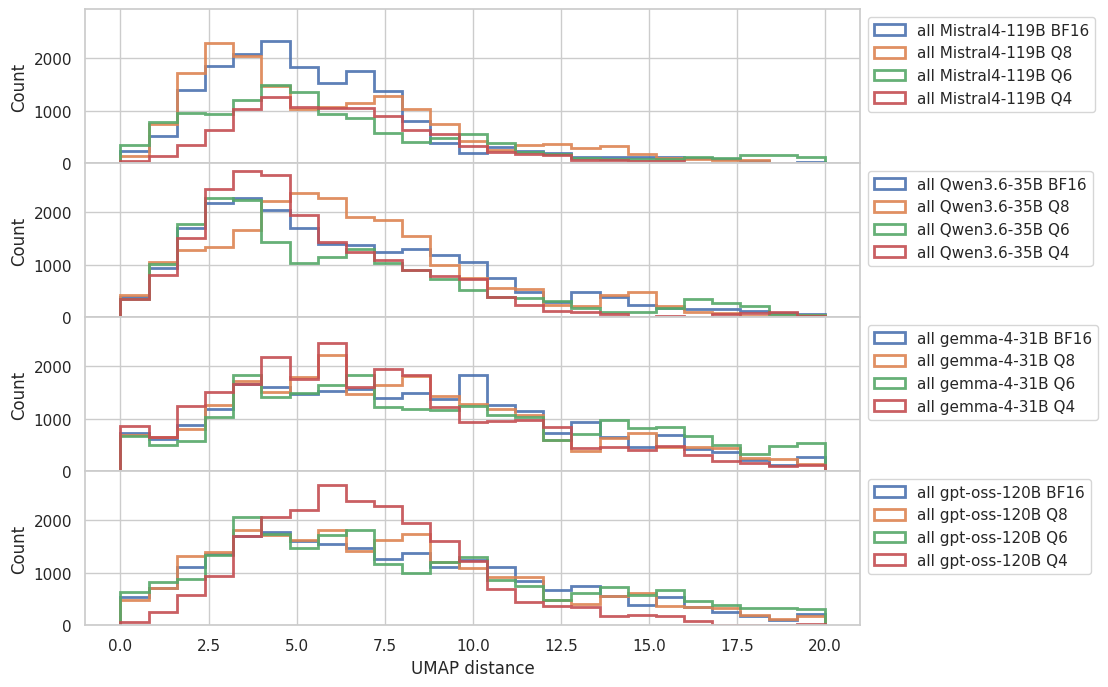

Mistral4-119B BF16 261
Qwen3.6-35B BF16 327
gemma-4-31B BF16 371
gpt-oss-120B BF16 344
Mistral4-119B Q8 250
Qwen3.6-35B Q8 328
gemma-4-31B Q8 365
gpt-oss-120B Q8 342
Mistral4-119B Q6 189
Qwen3.6-35B Q6 273
gemma-4-31B Q6 382
gpt-oss-120B Q6 360
Mistral4-119B Q4 142
Qwen3.6-35B Q4 289
gemma-4-31B Q4 375
gpt-oss-120B Q4 325


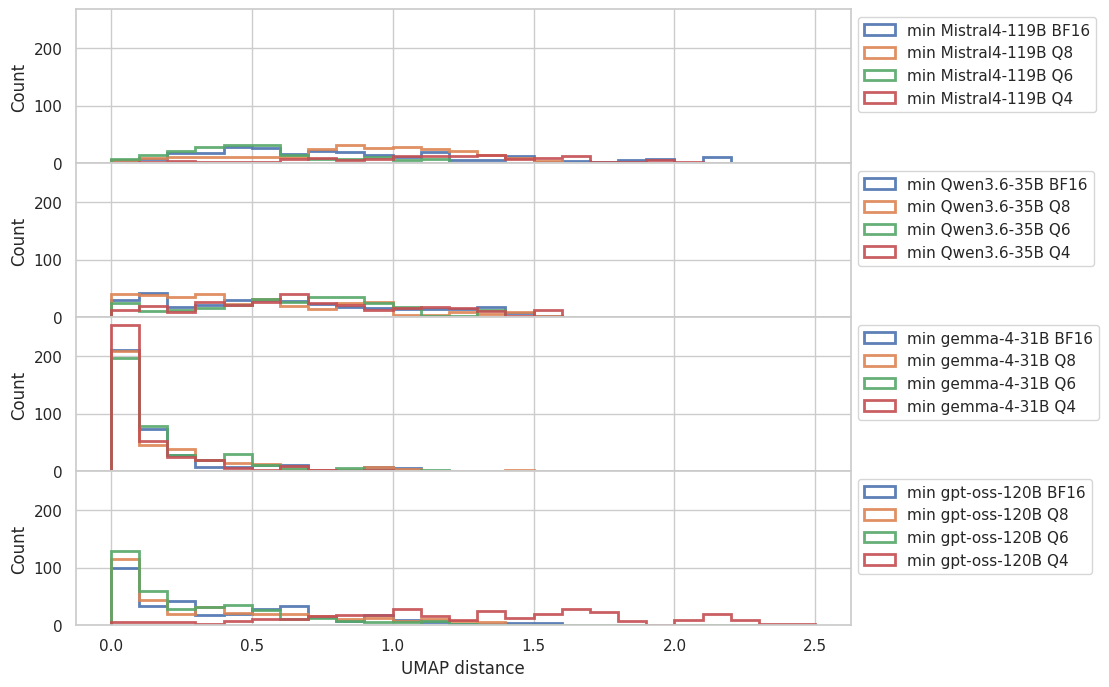

Mistral4-119B BF16 261
Qwen3.6-35B BF16 327
gemma-4-31B BF16 371
gpt-oss-120B BF16 344
Mistral4-119B Q8 250
Qwen3.6-35B Q8 328
gemma-4-31B Q8 365
gpt-oss-120B Q8 342
Mistral4-119B Q6 189
Qwen3.6-35B Q6 273
gemma-4-31B Q6 382
gpt-oss-120B Q6 360
Mistral4-119B Q4 142
Qwen3.6-35B Q4 289
gemma-4-31B Q4 375
gpt-oss-120B Q4 325


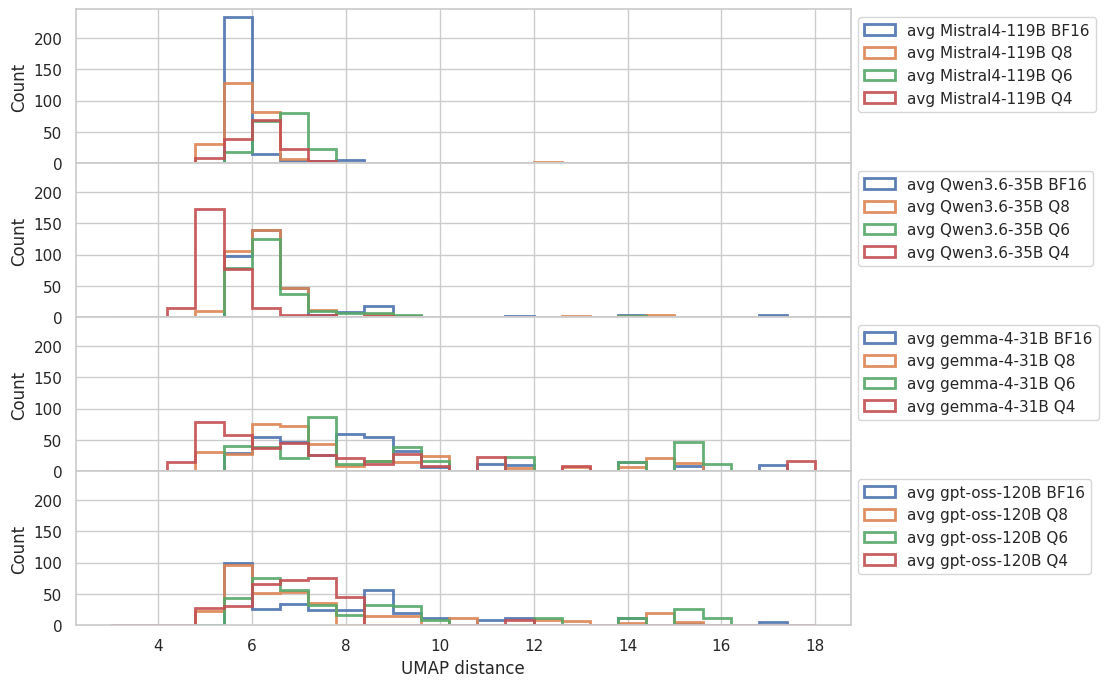

In [79]:
bins = 25

d_yminmax = {'all':(0,20), 'min':(0,2.5), 'avg':(3,18)}

for stats in ['all', 'min', 'avg']:
    fig, ax = plt.subplots(len(lst_models), 1, figsize=(10, 8), sharey=True)
    for q in lst_quants:
        for i,model in enumerate(lst_models):
            print(model,q, len(d_dist[q][model][stats]))
            ax[i].hist(d_dist[q][model][stats], label=f'{stats} {model} {q}', range=d_yminmax[stats], bins=bins, alpha=0.9, histtype='step', linewidth=2)
            ax[i].legend(loc='upper left', bbox_to_anchor=(1, 1))
            ax[i].set_ylabel('Count')
    ax[i].set_xlabel('UMAP distance')
    plt.subplots_adjust(hspace=0)
    #plt.tight_layout()
    plt.show()



In [29]:
d_smiles = get_all_smiles()
d_smiles['prompt'] = lst_smiles_prompt

In [30]:
for model in d_smiles:
    try:
        for quant in d_smiles[model]:
            print(f'{model:14s} {quant:5s} {len(d_smiles[model][quant])}')
    except:
        print(f'{model:14s}        {len(d_smiles[model])}')

Mistral4-119B  BF16  261
Mistral4-119B  Q8    250
Mistral4-119B  Q6    189
Mistral4-119B  Q4    142
Qwen3.6-35B    BF16  327
Qwen3.6-35B    Q8    328
Qwen3.6-35B    Q6    273
Qwen3.6-35B    Q4    289
gemma-4-31B    BF16  371
gemma-4-31B    Q8    365
gemma-4-31B    Q6    382
gemma-4-31B    Q4    375
gpt-oss-120B   BF16  344
gpt-oss-120B   Q8    342
gpt-oss-120B   Q6    360
gpt-oss-120B   Q4    325
prompt                69


In [31]:
d_sim_stats_df = {}
d_sim_stats = {}
d_sim = pairwise_tanimoto_stats(d_smiles)

for q in lst_quants:
    d_sim_stats[q] = {}

    for model in lst_models:
        d_sim_stats[q][model] = {}
        
        for stats in ['all', 'avg', 'max', 'med']:
            d_sim_stats[q][model][f'{stats} avg'] = np.average(d_sim[q][model][stats])
            d_sim_stats[q][model][f'{stats} med'] = np.median(d_sim[q][model][stats])
            d_sim_stats[q][model][f'{stats} std'] = np.std(d_sim[q][model][stats])
            d_sim_stats[q][model][f'{stats} max'] = np.max(d_sim[q][model][stats])

    d_sim_stats_df[q] = pd.DataFrame.from_dict(d_sim_stats[q], orient='index')


In [32]:
for q in lst_quants:
    print(q)
    display(d_sim_stats_df[q].style.format("{:.4f}"))

BF16


,all avg,all med,all std,all max,avg avg,avg med,avg std,avg max,max avg,max med,max std,max max,med avg,med med,med std,med max
Mistral4-119B,0.1115,0.1059,0.0423,0.7414,0.1115,0.1108,0.0218,0.2001,0.2147,0.2078,0.0668,0.7414,0.1076,0.1087,0.0208,0.1648
Qwen3.6-35B,0.1517,0.1429,0.0584,1.0000,0.1517,0.1518,0.0173,0.2053,0.3444,0.2963,0.1598,1.0000,0.1446,0.1458,0.0155,0.1889
gemma-4-31B,0.1718,0.1478,0.1029,1.0000,0.1718,0.1719,0.0226,0.2252,0.7633,0.8108,0.1473,1.0000,0.1504,0.1500,0.0177,0.1919
gpt-oss-120B,0.1561,0.1398,0.0824,0.9800,0.1561,0.1584,0.0270,0.2236,0.5311,0.5858,0.2313,0.9800,0.1419,0.1444,0.0204,0.1863


Q8


,all avg,all med,all std,all max,avg avg,avg med,avg std,avg max,max avg,max med,max std,max max,med avg,med med,med std,med max
Mistral4-119B,0.1160,0.1111,0.0450,0.7273,0.1160,0.1153,0.0256,0.1979,0.2215,0.2156,0.0677,0.7273,0.1121,0.1124,0.0249,0.1690
Qwen3.6-35B,0.1482,0.1386,0.0624,1.0000,0.1482,0.1459,0.0206,0.2212,0.3481,0.2762,0.1927,1.0000,0.1401,0.1385,0.0172,0.1919
gemma-4-31B,0.1707,0.1468,0.1019,1.0000,0.1707,0.1724,0.0238,0.2252,0.7434,0.7714,0.1549,1.0000,0.1495,0.1485,0.0186,0.1919
gpt-oss-120B,0.1568,0.1389,0.0862,1.0000,0.1568,0.1594,0.0282,0.2236,0.5508,0.6101,0.2505,1.0000,0.1415,0.1444,0.0206,0.1863


Q6


,all avg,all med,all std,all max,avg avg,avg med,avg std,avg max,max avg,max med,max std,max max,med avg,med med,med std,med max
Mistral4-119B,0.1209,0.1154,0.0421,0.5789,0.1209,0.1202,0.0232,0.1786,0.2205,0.2118,0.0581,0.5789,0.1175,0.1163,0.0230,0.1771
Qwen3.6-35B,0.1533,0.1444,0.0584,1.0000,0.1533,0.1536,0.0194,0.2176,0.3290,0.2927,0.1428,1.0000,0.1460,0.1456,0.0184,0.1900
gemma-4-31B,0.1743,0.1495,0.1046,1.0000,0.1743,0.1732,0.0229,0.2252,0.7721,0.8182,0.1389,1.0000,0.1524,0.1520,0.0175,0.1957
gpt-oss-120B,0.1592,0.1395,0.0917,1.0000,0.1592,0.1600,0.0296,0.2252,0.5968,0.6780,0.2573,1.0000,0.1426,0.1443,0.0210,0.1919


Q4


,all avg,all med,all std,all max,avg avg,avg med,avg std,avg max,max avg,max med,max std,max max,med avg,med med,med std,med max
Mistral4-119B,0.1066,0.1029,0.0422,0.4342,0.1066,0.1072,0.0260,0.1641,0.2011,0.1976,0.0646,0.4342,0.1039,0.1031,0.0260,0.1649
Qwen3.6-35B,0.1521,0.1429,0.0547,0.8429,0.1521,0.1517,0.0176,0.2095,0.3008,0.2809,0.0843,0.8429,0.1458,0.1456,0.0167,0.1959
gemma-4-31B,0.1725,0.1475,0.1057,1.0000,0.1725,0.1713,0.0230,0.2236,0.7887,0.8246,0.1348,1.0000,0.1504,0.1477,0.0172,0.1881
gpt-oss-120B,0.1121,0.1062,0.0455,0.9844,0.1121,0.1124,0.0227,0.1853,0.2337,0.2167,0.1061,0.9844,0.1076,0.1096,0.0213,0.1667


In [33]:
tmp = {}
for stats in ['max med', 'max avg', 'max std', 'max max']:
    tmp[stats] = {}
    for q in lst_quants:
        tmp[stats][q] = {}
    
        for m in lst_models:
            tmp[stats][q][m] = d_sim_stats[q][m][stats]

In [34]:
for stats in ['max med', 'max avg', 'max std', 'max max']:
    print('Tanimoto Similarity to closest reference molecule -', stats.replace('max ', ''))
    display(pd.DataFrame.from_dict(tmp[stats], orient='index').style.format("{:.4f}"))
    print()

Tanimoto Similarity to closest reference molecule - med


,Mistral4-119B,Qwen3.6-35B,gemma-4-31B,gpt-oss-120B
BF16,0.2078,0.2963,0.8108,0.5858
Q8,0.2156,0.2762,0.7714,0.6101
Q6,0.2118,0.2927,0.8182,0.6780
Q4,0.1976,0.2809,0.8246,0.2167



Tanimoto Similarity to closest reference molecule - avg


,Mistral4-119B,Qwen3.6-35B,gemma-4-31B,gpt-oss-120B
BF16,0.2147,0.3444,0.7633,0.5311
Q8,0.2215,0.3481,0.7434,0.5508
Q6,0.2205,0.3290,0.7721,0.5968
Q4,0.2011,0.3008,0.7887,0.2337



Tanimoto Similarity to closest reference molecule - std


,Mistral4-119B,Qwen3.6-35B,gemma-4-31B,gpt-oss-120B
BF16,0.0668,0.1598,0.1473,0.2313
Q8,0.0677,0.1927,0.1549,0.2505
Q6,0.0581,0.1428,0.1389,0.2573
Q4,0.0646,0.0843,0.1348,0.1061



Tanimoto Similarity to closest reference molecule - max


,Mistral4-119B,Qwen3.6-35B,gemma-4-31B,gpt-oss-120B
BF16,0.7414,1.0000,1.0000,0.9800
Q8,0.7273,1.0000,1.0000,1.0000
Q6,0.5789,1.0000,1.0000,1.0000
Q4,0.4342,0.8429,1.0000,0.9844


Mistral4-119B BF16 18009
Qwen3.6-35B BF16 22563
gemma-4-31B BF16 25599
gpt-oss-120B BF16 23736
Mistral4-119B Q8 17250
Qwen3.6-35B Q8 22632
gemma-4-31B Q8 25185
gpt-oss-120B Q8 23598
Mistral4-119B Q6 13041
Qwen3.6-35B Q6 18837
gemma-4-31B Q6 26358
gpt-oss-120B Q6 24840


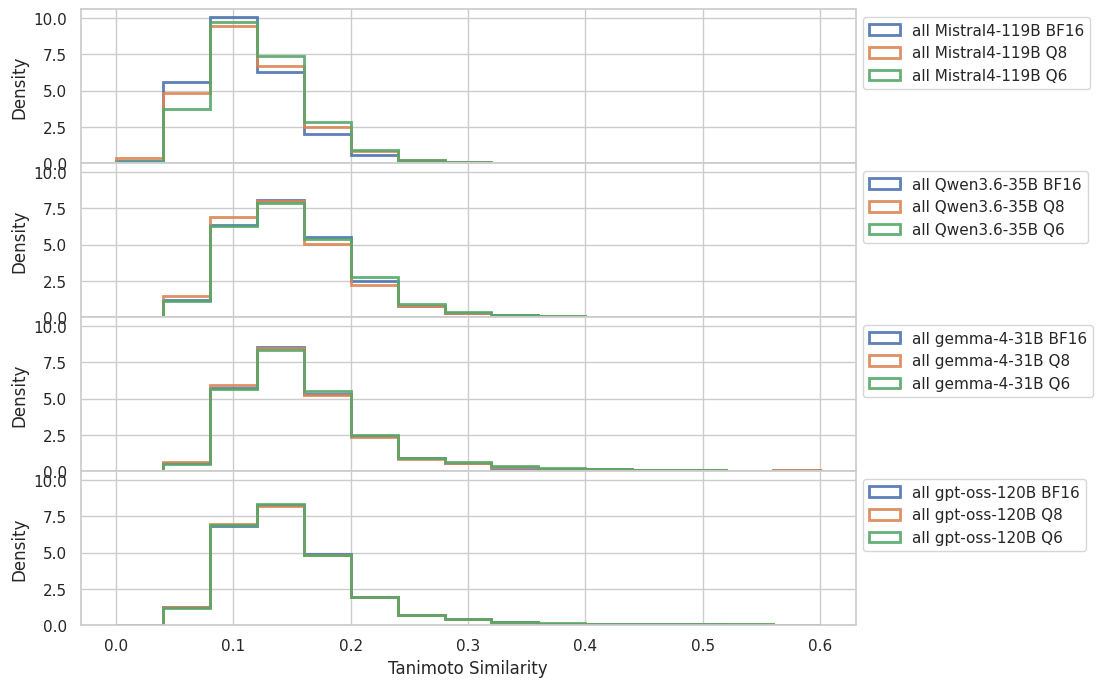

Mistral4-119B BF16 261
Qwen3.6-35B BF16 327
gemma-4-31B BF16 371
gpt-oss-120B BF16 344
Mistral4-119B Q8 250
Qwen3.6-35B Q8 328
gemma-4-31B Q8 365
gpt-oss-120B Q8 342
Mistral4-119B Q6 189
Qwen3.6-35B Q6 273
gemma-4-31B Q6 382
gpt-oss-120B Q6 360


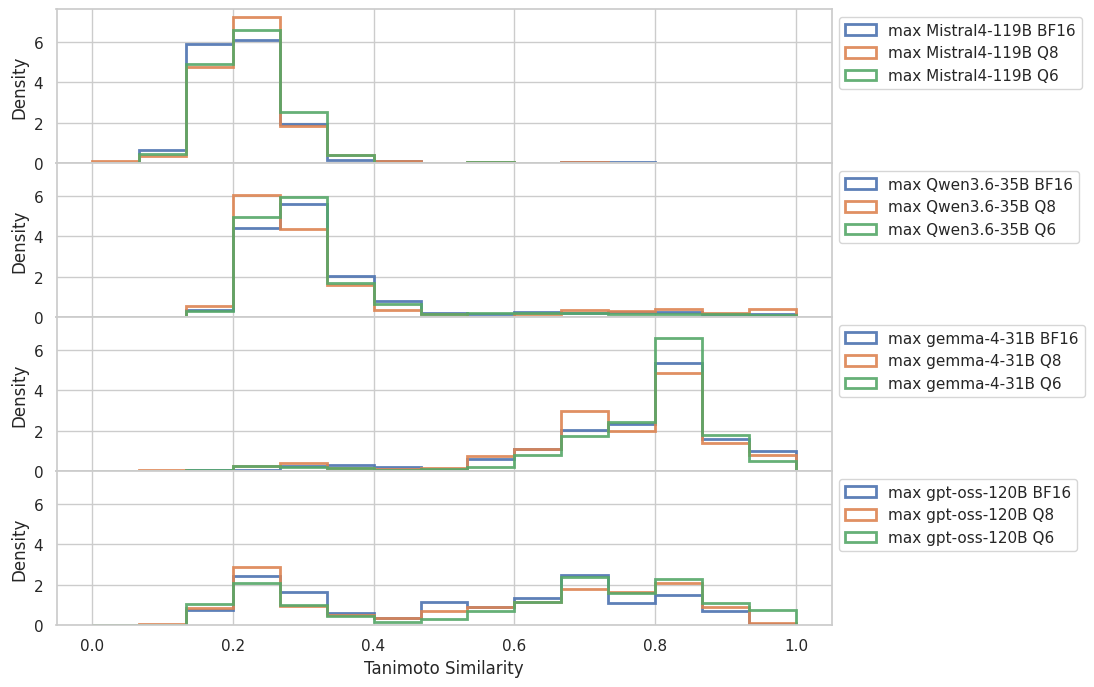

Mistral4-119B BF16 261
Qwen3.6-35B BF16 327
gemma-4-31B BF16 371
gpt-oss-120B BF16 344
Mistral4-119B Q8 250
Qwen3.6-35B Q8 328
gemma-4-31B Q8 365
gpt-oss-120B Q8 342
Mistral4-119B Q6 189
Qwen3.6-35B Q6 273
gemma-4-31B Q6 382
gpt-oss-120B Q6 360


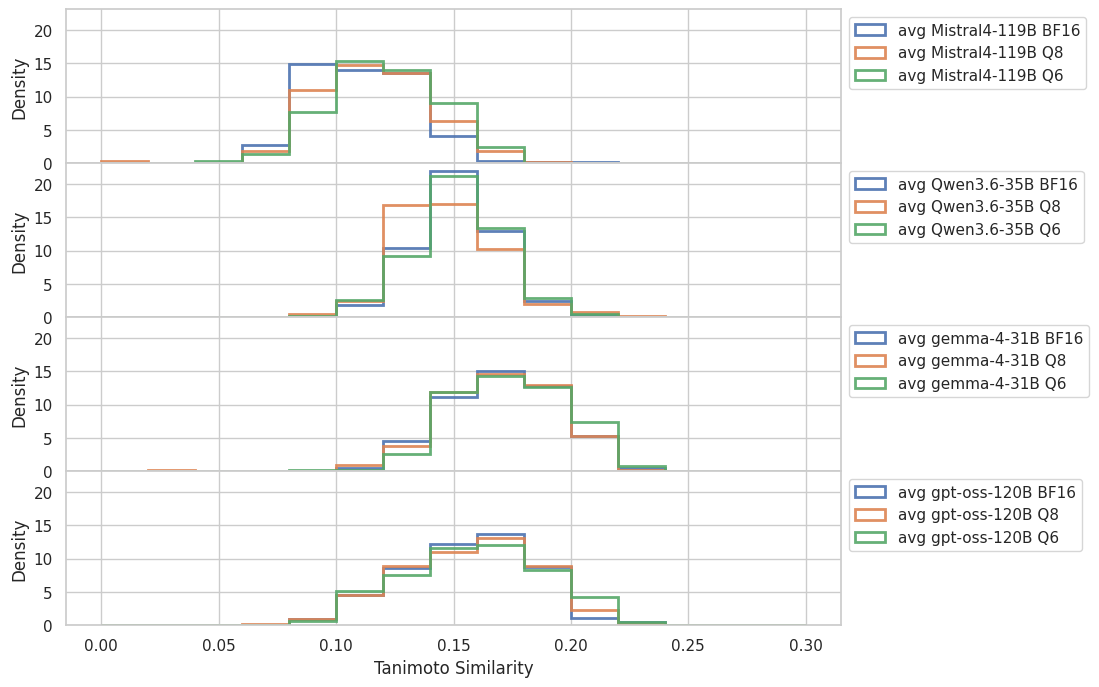

In [101]:
bins = 15

d_sim_yminmax = {'all':(0,0.6), 'max':(0,1), 'avg':(0,0.30)}

for stats in ['all', 'max', 'avg']:
    fig, ax = plt.subplots(len(lst_models), 1, figsize=(10, 8), sharey=True)
    for q in ['BF16', 'Q8', 'Q6']:
        for i,model in enumerate(lst_models):
            print(model,q, len(d_sim[q][model][stats]))
            ax[i].hist(d_sim[q][model][stats], label=f'{stats} {model} {q}', range=d_sim_yminmax[stats], bins=bins, alpha=0.9, histtype='step', linewidth=2, density=True)
            ax[i].legend(loc='upper left', bbox_to_anchor=(1, 1))
            ax[i].set_ylabel('Density')
    ax[i].set_xlabel('Tanimoto Similarity')
    plt.subplots_adjust(hspace=0)
    #plt.tight_layout()
    plt.show()



In [ ]:
def pairwise_tanimoto_stats(d_smiles):
    d = {}
    
    lst_smi_prompt = d_smiles['prompt']
    lst_mol_prompt = [Chem.MolFromSmiles(smi) for smi in lst_smi_prompt]
    lst_fps_prompt = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol_prompt]
    total_prompt = len(lst_smi_prompt)
    
    for q in lst_quants:
        d[q] = {}
        
        for m in lst_models:
            d[q][m] = {}
            d[q][m]['all'] = []
            d[q][m]['avg'] = []
            d[q][m]['max'] = []
            d[q][m]['med'] = []
            
            
            lst_smi = d_smiles[m][q]
            lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
            lst_fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]
            total = len(lst_smi)
    
    
            for m1 in lst_fps:
                lst_sim = []
                for m2 in lst_fps_prompt:
                    sim = DataStructs.TanimotoSimilarity(m1, m2)
                    lst_sim.append(sim)
                    
                d[q][m]['all'] += lst_sim
                d[q][m]['avg'].append(float(np.average(np.array(lst_sim))))
                d[q][m]['max'].append(float(np.max(np.array(lst_sim))))
                d[q][m]['med'].append(float(np.median(np.array(lst_sim))))

In [55]:
from rdkit.Chem import Draw


Mistral4-119B   BF16  0/261 0.00%
Mistral4-119B   Q8    0/250 0.00%
Mistral4-119B   Q6    0/189 0.00%
Mistral4-119B   Q4    0/142 0.00%
prompt = CC1=NNC(NC2=NN3C(C(CN4CCOCC4)=C2)=NC(C)=C3CC5=CC=C(C=C5F)Cl)=C1
model  =  Cc1cc(Nc2cc(CN3CCOCC3)c3nc(C)c(Cc4ccc(Cl)cc4F)n3n2)[nH]n1


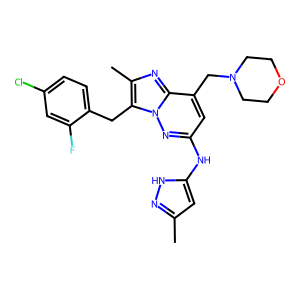

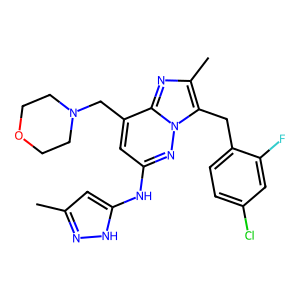


prompt = O=C1NC2=CC(C(OC)=O)=CC=C2/C1=C(NC3=CC=C(N(C(CN4CCN(C)CC4)=O)C)C=C3)\\C5=CC=CC=C5
model  =  COC(=O)c1ccc2c(c1)NC(=O)/C2=C(/Nc1ccc(N(C)C(=O)CN2CCN(C)CC2)cc1)c1ccccc1


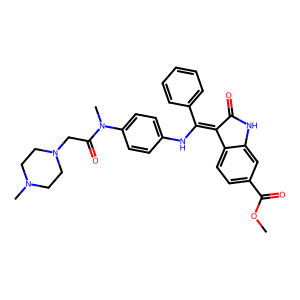

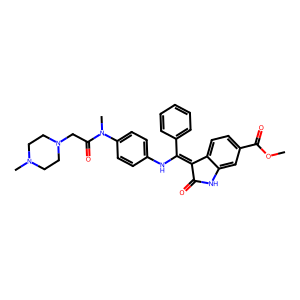


Qwen3.6-35B     BF16  2/327 0.61%
prompt = N#CC1=C(C2=CC(NC(/C=C/CN(C)C)=O)=C(OCC)C=C2N=C1)NC3=CC(Cl)=C(C=C3)F
model  =  CCOc1cc2ncc(C#N)c(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)/C=C/CN(C)C


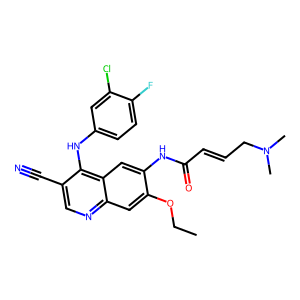

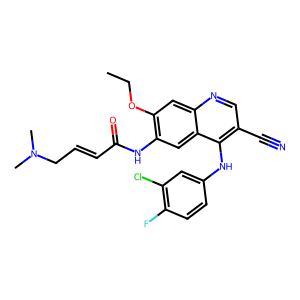


prompt = FC(C(Cl)=CC=C1)=C1O[C@H](CC2)CC[C@@]2(C(O)=O)CC3=CC=CC(NC4=NC=CS4)=N3
model  =  O=C(O)[C@]1(Cc2cccc(Nc3nccs3)n2)CC[C@@H](Oc2cccc(Cl)c2F)CC1


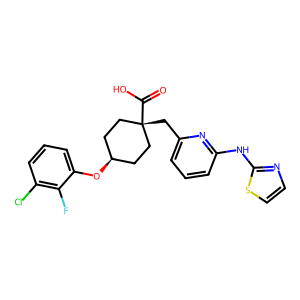

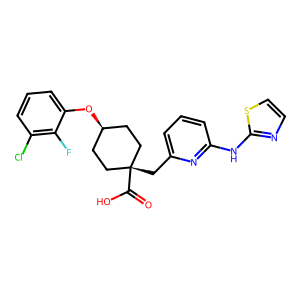


prompt = CS(=O)(N(C)C1=NC=CC=C1CNC2=NC(NC3=CC4=C(C=C3)NC(C4)=O)=NC=C2C(F)(F)F)=O
model  =  CN(c1ncccc1CNc1nc(Nc2ccc3c(c2)CC(=O)N3)ncc1C(F)(F)F)S(C)(=O)=O


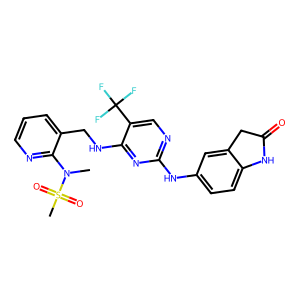

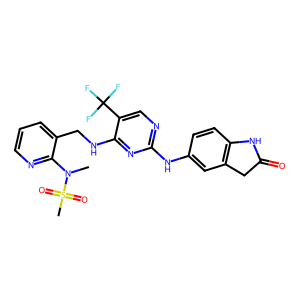


prompt = CC1=CC(NC2=NC(SC3=CC=C(C=C3)NC(C4CC4)=O)=NC(N5CCN(CC5)C)=C2)=NN1
model  =  Cc1cc(Nc2cc(N3CCN(C)CC3)nc(Sc3ccc(NC(=O)C4CC4)cc3)n2)n[nH]1


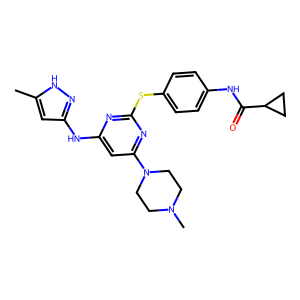

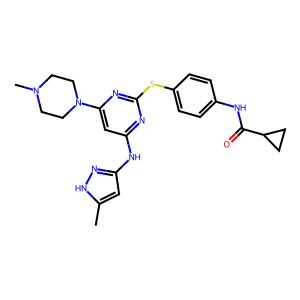


prompt = N#CC1=C(C2=CC(NC(/C=C/CN(C)C)=O)=C(OCC)C=C2N=C1)NC3=CC(Cl)=C(C=C3)F
model  =  CCOc1cc2ncc(C#N)c(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)/C=C/CN(C)C


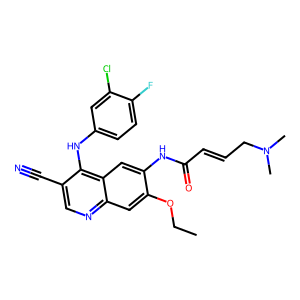

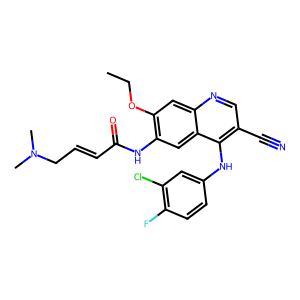


prompt = ClC1=C(C=CC(NC2=NC=NC3=C2C=C(C(OC)=C3)OCCCN4CCOCC4)=C1)F
model  =  COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1


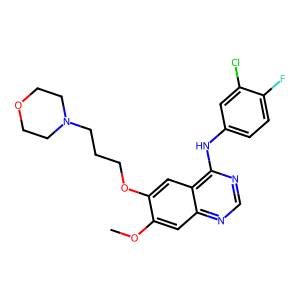

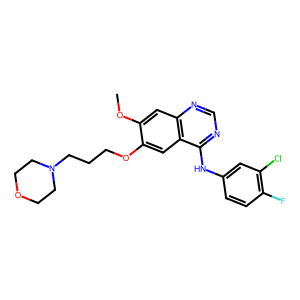


Qwen3.6-35B     Q8    6/328 1.83%
prompt = NC1=C2C(N(C=C2C3=CC=CC(OCC4=CC=CC=C4)=C3)[C@H]5C[C@@H](C5)CN6CCCC6)=NC=N1
model  =  Nc1ncnc2c1c(-c1cccc(OCc3ccccc3)c1)cn2[C@H]1C[C@@H](CN2CCCC2)C1


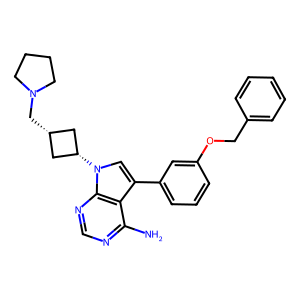

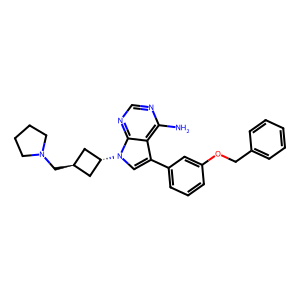


prompt = CC1=CC(NC2=NC(SC3=CC=C(C=C3)NC(C4CC4)=O)=NC(N5CCN(CC5)C)=C2)=NN1
model  =  Cc1cc(Nc2cc(N3CCN(C)CC3)nc(Sc3ccc(NC(=O)C4CC4)cc3)n2)n[nH]1


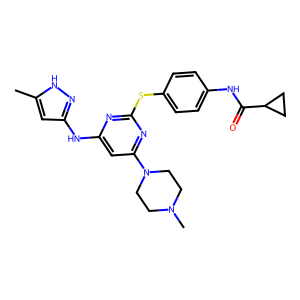

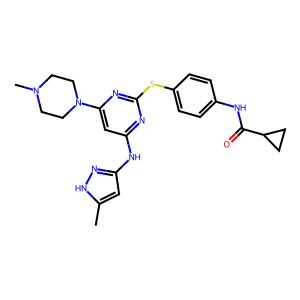


Qwen3.6-35B     Q6    2/273 0.73%
Qwen3.6-35B     Q4    0/289 0.00%
prompt = O=C(NC1=CC=CC(Cl)=C1)NC2=NC=C(S2)CCNC3=C4C(C=CS4)=NC=N3.OS(C)(=O)=O
model  =  CS(=O)(=O)O.O=C(Nc1cccc(Cl)c1)Nc1ncc(CCNc2ncnc3ccsc23)s1


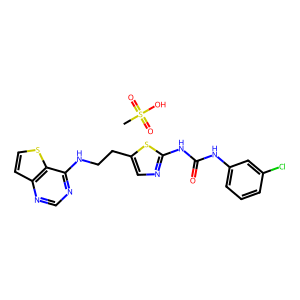

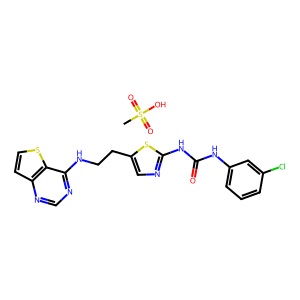


prompt = CN1CCN(C2=CC=C(C=C2)NC3=NC=C(C(OC4=CC(NC(C=C)=O)=CC=C4)=N3)Cl)CC1
model  =  C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(C)CC4)cc3)ncc2Cl)c1


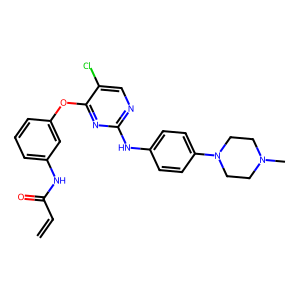

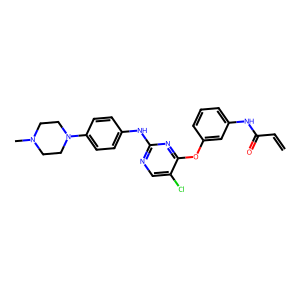


prompt = O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCCC4)=NC=C2C)=C1)(NC(C)(C)C)=O
model  =  Cc1cnc(Nc2ccc(OCCN3CCCC3)cc2)nc1Nc1cccc(S(=O)(=O)NC(C)(C)C)c1


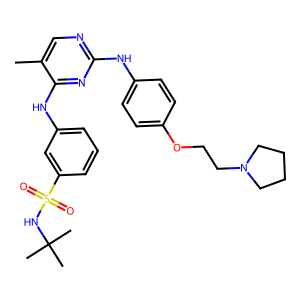

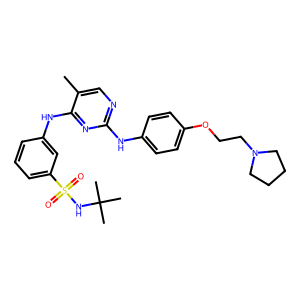


prompt = COC1=NC=C(C=C1NS(C2=CC=C(C=C2F)F)(=O)=O)C3=CC=C(C4=C3)N=CC=C4C5=CN=NC=C5
model  =  COc1ncc(-c2ccc3nccc(-c4ccnnc4)c3c2)cc1NS(=O)(=O)c1ccc(F)cc1F


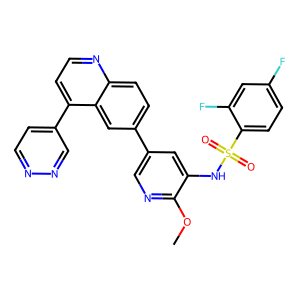

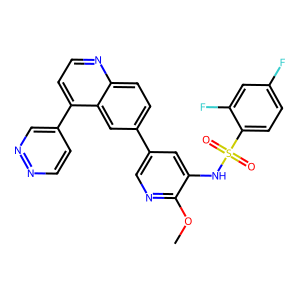


prompt = O=S(C1=CC=C(C2=CC=CN3C2=NC(NC4=CC=CC(N5CCN(C)CC5)=C4)=N3)C=C1)(C)=O
model  =  CN1CCN(c2cccc(Nc3nc4c(-c5ccc(S(C)(=O)=O)cc5)cccn4n3)c2)CC1


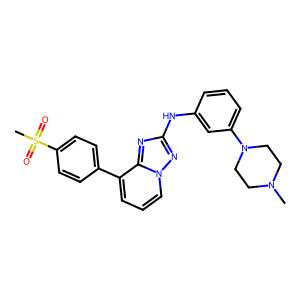

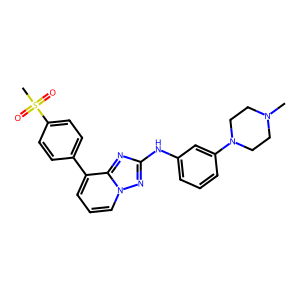


prompt = O=C(NC1=NC2=C(C3=NCCN13)C=CC(OC)=C2OC)C4=CC=CN=C4
model  =  COc1ccc2c(c1OC)N=C(NC(=O)c1cccnc1)N1CCN=C21


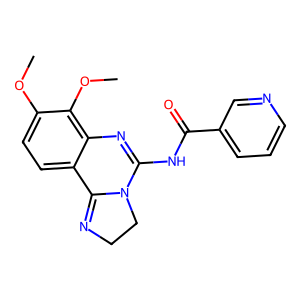

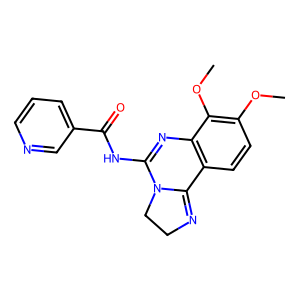


prompt = N#CC[C@H](C1CCCC1)N2N=CC(C3=C4C=CNC4=NC=N3)=C2
model  =  N#CC[C@H](C1CCCC1)n1cc(-c2ncnc3[nH]ccc23)cn1


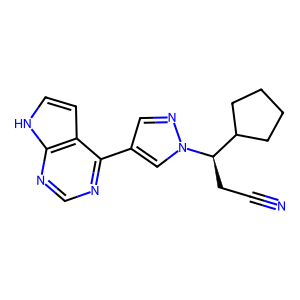

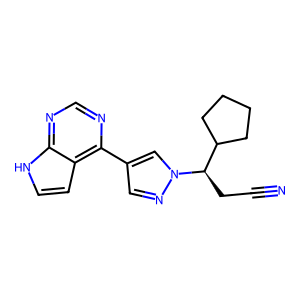


prompt = CN1CCN(C2=CC=C(C=C2)NC3=NC=C(C(OC4=CC(NC(C=C)=O)=CC=C4)=N3)Cl)CC1
model  =  C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(C)CC4)cc3)ncc2Cl)c1


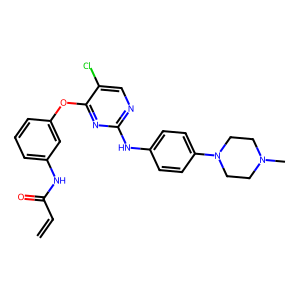

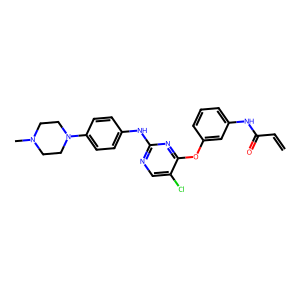


prompt = O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)N4CCN(CC4)C)=NC=C2C)=C1)(NC(C)(C)C)=O
model  =  Cc1cnc(Nc2ccc(N3CCN(C)CC3)cc2)nc1Nc1cccc(S(=O)(=O)NC(C)(C)C)c1


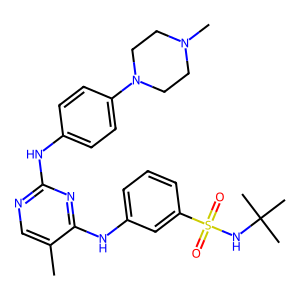

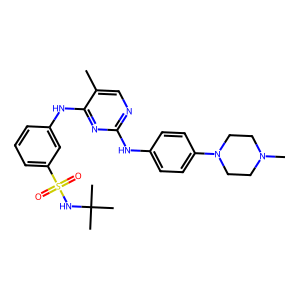


prompt = N#CC1=C(C2=CC(NC(/C=C/CN(C)C)=O)=C(OCC)C=C2N=C1)NC3=CC(Cl)=C(C=C3)F
model  =  CCOc1cc2ncc(C#N)c(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)/C=C/CN(C)C


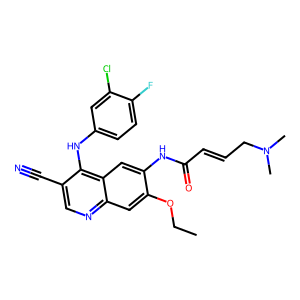

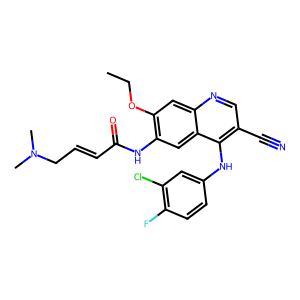


prompt = N#CC1=C(C2=CC(NC(/C=C/CN(C)C)=O)=C(OCC)C=C2N=C1)NC3=CC(Cl)=C(C=C3)F
model  =  CCOc1cc2ncc(C#N)c(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)/C=C/CN(C)C


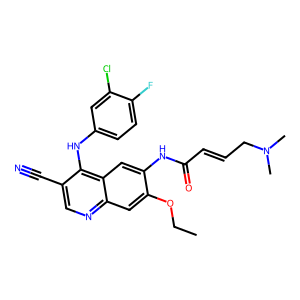

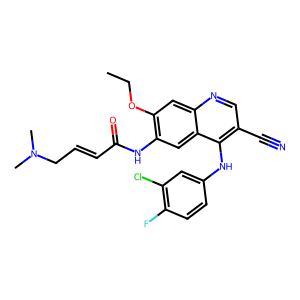


prompt = O=C(N)C1=C(C=C2N=CC=C(C2=C1)OC3=CC=C(C(Cl)=C3)NC(NC4CC4)=O)OC
model  =  COc1cc2nccc(Oc3ccc(NC(=O)NC4CC4)c(Cl)c3)c2cc1C(N)=O


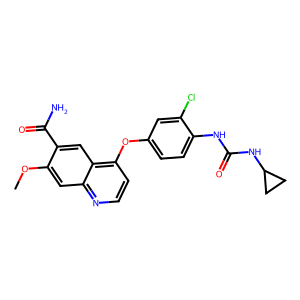

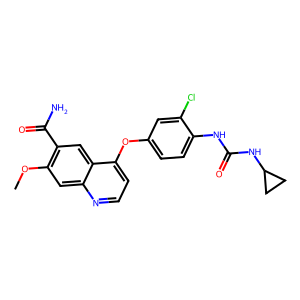


prompt = ClC1=CC=C([C@@H](CNC(C)C)C(N2CCN(C3=C([C@H](C)C[C@H]4O)C4=NC=N3)CC2)=O)C=C1
model  =  CC(C)NC[C@@H](C(=O)N1CCN(c2ncnc3c2[C@H](C)C[C@H]3O)CC1)c1ccc(Cl)cc1


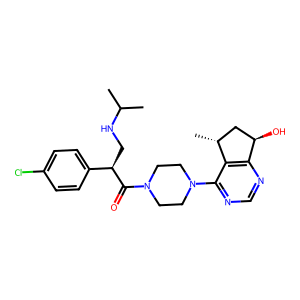

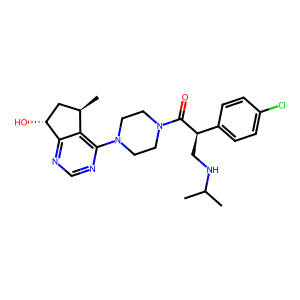


prompt = O=C(C1=C(SC2=CC3=C(C(/C=C/C4=CC=CC=N4)=NN3)C=C2)C=CC=C1)NC
model  =  CNC(=O)c1ccccc1Sc1ccc2c(/C=C/c3ccccn3)n[nH]c2c1


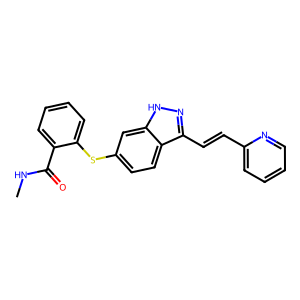

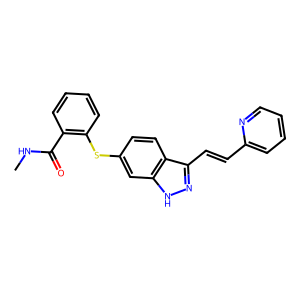


prompt = CN1CCN(C2=CC=C(C=C2)NC3=NC=C(C(OC4=CC(NC(C=C)=O)=CC=C4)=N3)Cl)CC1
model  =  C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(C)CC4)cc3)ncc2Cl)c1


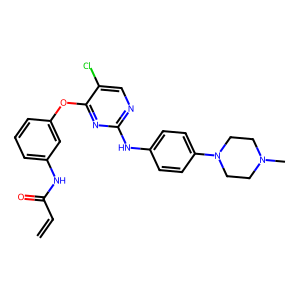

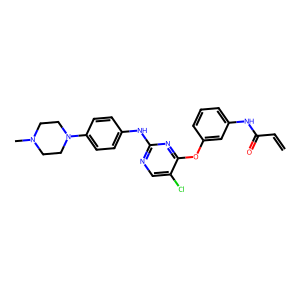


gemma-4-31B     BF16  15/371 4.04%
prompt = O=S(C1=CC=C(C2=CC=CN3C2=NC(NC4=CC=CC(N5CCN(C)CC5)=C4)=N3)C=C1)(C)=O
model  =  CN1CCN(c2cccc(Nc3nc4c(-c5ccc(S(C)(=O)=O)cc5)cccn4n3)c2)CC1


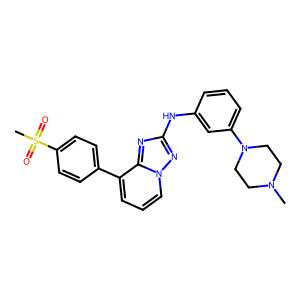

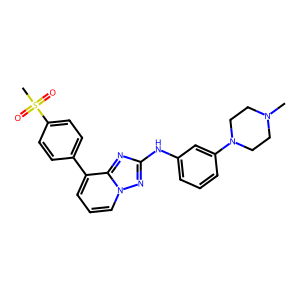


prompt = O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCCC4)=NC=C2C)=C1)(NC(C)(C)C)=O
model  =  Cc1cnc(Nc2ccc(OCCN3CCCC3)cc2)nc1Nc1cccc(S(=O)(=O)NC(C)(C)C)c1


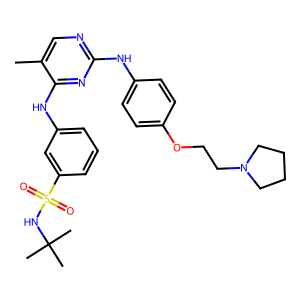

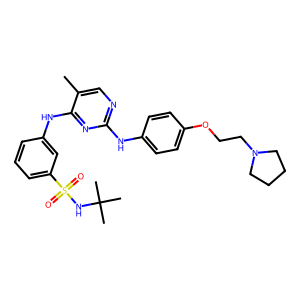


prompt = O=S(C1=CC=C(C2=CC=CN3C2=NC(NC4=CC=CC(N5CCN(C)CC5)=C4)=N3)C=C1)(C)=O
model  =  CN1CCN(c2cccc(Nc3nc4c(-c5ccc(S(C)(=O)=O)cc5)cccn4n3)c2)CC1


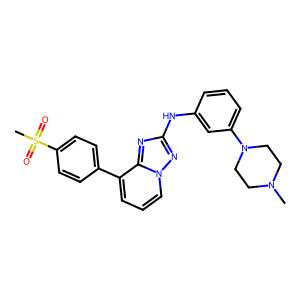

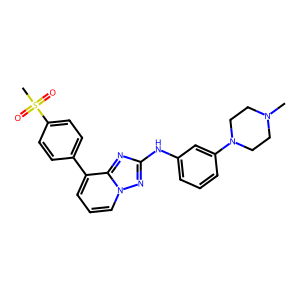


prompt = O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)N4CCN(CC4)C)=NC=C2C)=C1)(NC(C)(C)C)=O
model  =  Cc1cnc(Nc2ccc(N3CCN(C)CC3)cc2)nc1Nc1cccc(S(=O)(=O)NC(C)(C)C)c1


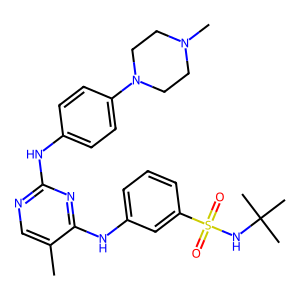

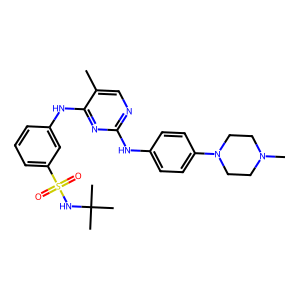


prompt = O/N=C1CCC2=CC(C3=C(NC(C4=CC=C(C=C4)OCCN(C)C)=N3)C5=CC=NC=C5)=CC=C/12
model  =  CN(C)CCOc1ccc(-c2nc(-c3ccc4c(c3)CC/C4=N/O)c(-c3ccncc3)[nH]2)cc1


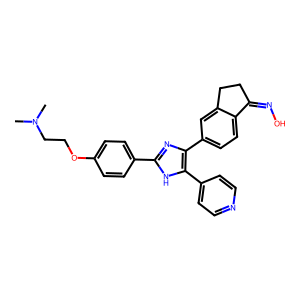

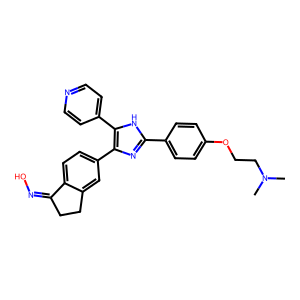


prompt = FC(C(Cl)=CC=C1)=C1O[C@H](CC2)CC[C@@]2(C(O)=O)CC3=CC=CC(NC4=NC=CS4)=N3
model  =  O=C(O)[C@]1(Cc2cccc(Nc3nccs3)n2)CC[C@@H](Oc2cccc(Cl)c2F)CC1


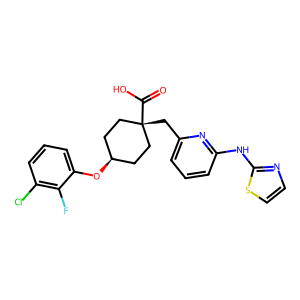

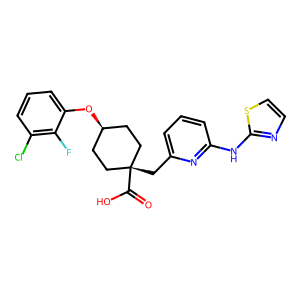


prompt = CS(=O)(N(C)C1=NC=CC=C1CNC2=NC(NC3=CC4=C(C=C3)NC(C4)=O)=NC=C2C(F)(F)F)=O
model  =  CN(c1ncccc1CNc1nc(Nc2ccc3c(c2)CC(=O)N3)ncc1C(F)(F)F)S(C)(=O)=O


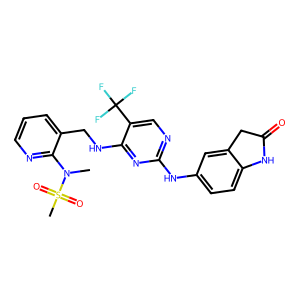

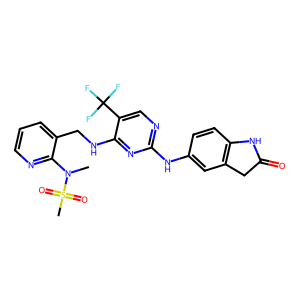


prompt = O=C1[C@H](N(C2=C(N1C)C=NC(NC3=CC=C(C(NC4CCN(C)CC4)=O)C=C3OC)=N2)C5CCCC5)CC
model  =  CC[C@@H]1C(=O)N(C)c2cnc(Nc3ccc(C(=O)NC4CCN(C)CC4)cc3OC)nc2N1C1CCCC1


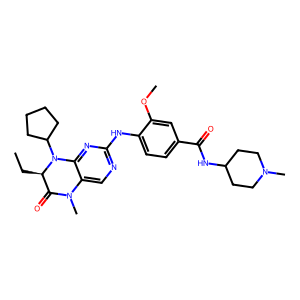

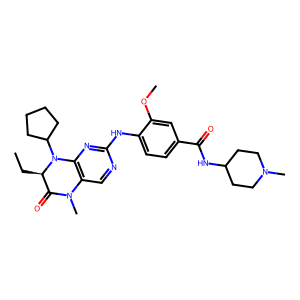


prompt = CN1CCN(C2=CC=C(C=C2)NC3=NC=C(C(OC4=CC(NC(C=C)=O)=CC=C4)=N3)Cl)CC1
model  =  C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(C)CC4)cc3)ncc2Cl)c1


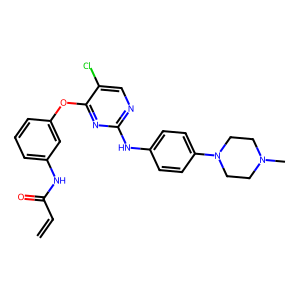

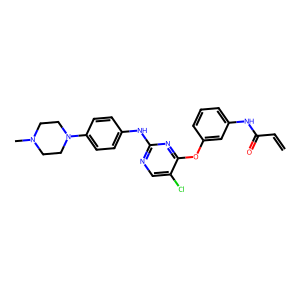


prompt = CN1CCN(C2=CC=C(C=C2)NC3=NC=C(C(OC4=CC(NC(C=C)=O)=CC=C4)=N3)Cl)CC1
model  =  C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(C)CC4)cc3)ncc2Cl)c1


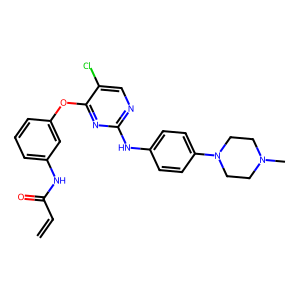

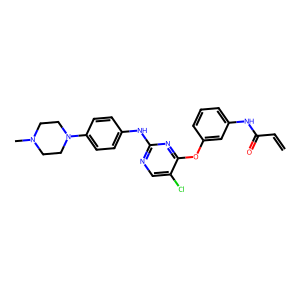


gemma-4-31B     Q8    10/365 2.74%
prompt = CN1CCN(C2=CC=C(C=C2)NC3=NC=C(C(OC4=CC(NC(C=C)=O)=CC=C4)=N3)Cl)CC1
model  =  C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(C)CC4)cc3)ncc2Cl)c1


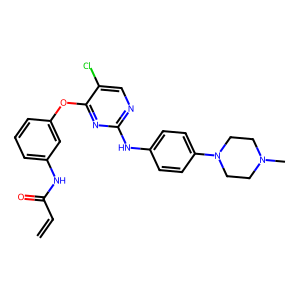

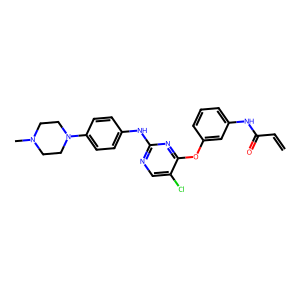


prompt = CN1CCN(C2=CC=C(C=C2)NC3=NC=C(C(OC4=CC(NC(C=C)=O)=CC=C4)=N3)Cl)CC1
model  =  C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(C)CC4)cc3)ncc2Cl)c1


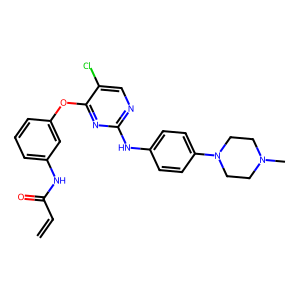

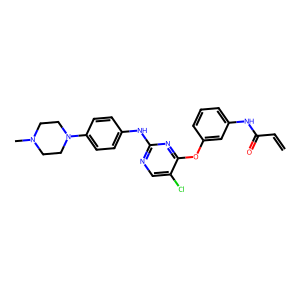


prompt = O=C(NC1=C(C=C2C(C(NC3=CC(Cl)=C(C=C3)F)=NC=N2)=C1)O[C@H]4CCOC4)/C=C/CN(C)C
model  =  CN(C)C/C=C/C(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1O[C@H]1CCOC1


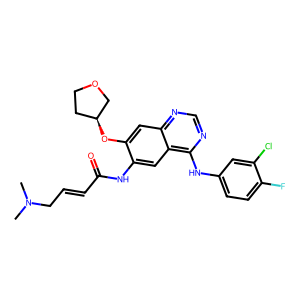

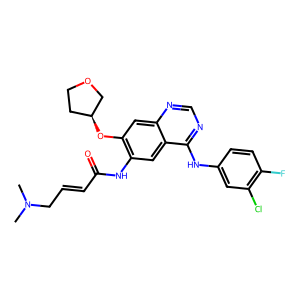


prompt = CS(=O)(N(C)C1=NC=CC=C1CNC2=NC(NC3=CC4=C(C=C3)NC(C4)=O)=NC=C2C(F)(F)F)=O
model  =  CN(c1ncccc1CNc1nc(Nc2ccc3c(c2)CC(=O)N3)ncc1C(F)(F)F)S(C)(=O)=O


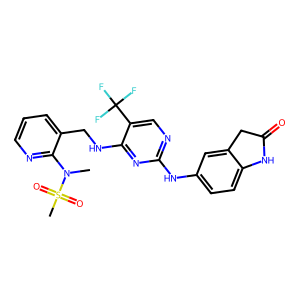

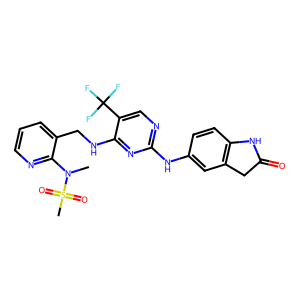


gemma-4-31B     Q6    4/382 1.05%
prompt = CN1CCN(C2=CC=C(C=C2)NC3=NC=C(C(OC4=CC(NC(C=C)=O)=CC=C4)=N3)Cl)CC1
model  =  C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(C)CC4)cc3)ncc2Cl)c1


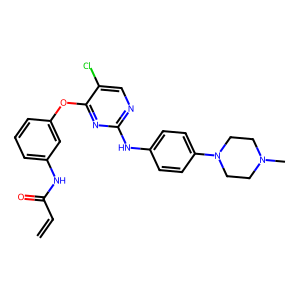

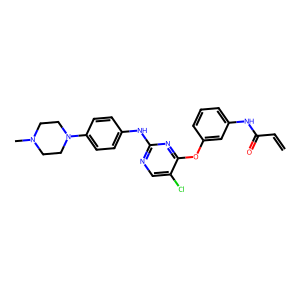


prompt = COC1=CC2=NC=NC(NC3=CC=CC(Cl)=C3)=C2C=C1OC
model  =  COc1cc2ncnc(Nc3cccc(Cl)c3)c2cc1OC


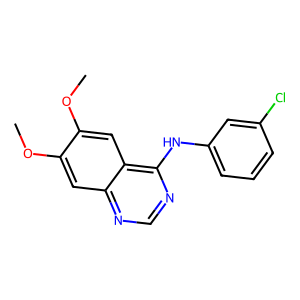

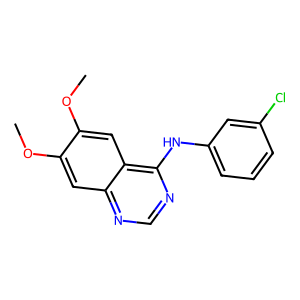


prompt = COC1=CC2=NC=NC(NC3=CC=CC(Cl)=C3)=C2C=C1OC
model  =  COc1cc2ncnc(Nc3cccc(Cl)c3)c2cc1OC


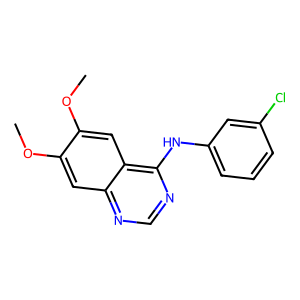

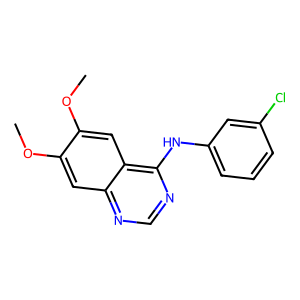


prompt = CN1CCN(C2=CC=C(C=C2)NC3=NC=C(C(OC4=CC(NC(C=C)=O)=CC=C4)=N3)Cl)CC1
model  =  C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(C)CC4)cc3)ncc2Cl)c1


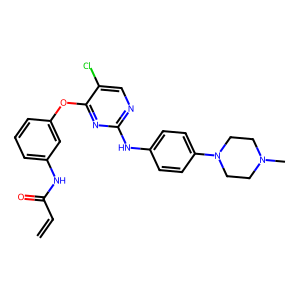

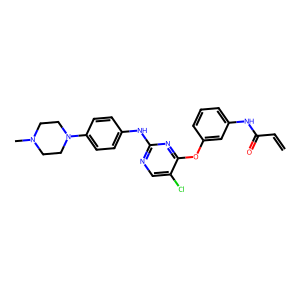


prompt = O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)N4CCN(CC4)C)=NC=C2C)=C1)(NC(C)(C)C)=O
model  =  Cc1cnc(Nc2ccc(N3CCN(C)CC3)cc2)nc1Nc1cccc(S(=O)(=O)NC(C)(C)C)c1


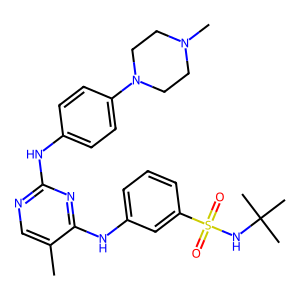

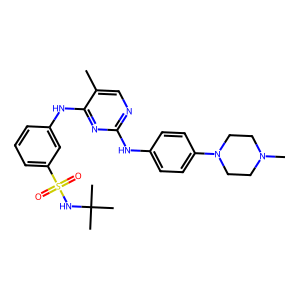


prompt = CS(=O)(N(C)C1=NC=CC=C1CNC2=NC(NC3=CC4=C(C=C3)NC(C4)=O)=NC=C2C(F)(F)F)=O
model  =  CN(c1ncccc1CNc1nc(Nc2ccc3c(c2)CC(=O)N3)ncc1C(F)(F)F)S(C)(=O)=O


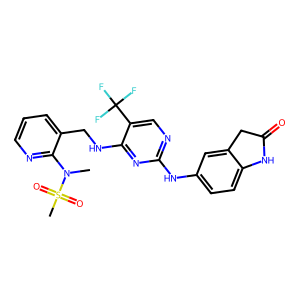

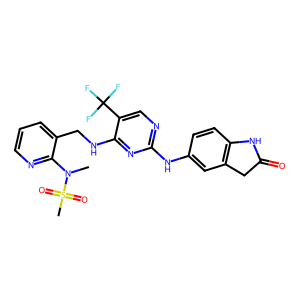


prompt = CN1CCN(C2=CC=C(C=C2)NC3=NC=C(C(OC4=CC(NC(C=C)=O)=CC=C4)=N3)Cl)CC1
model  =  C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(C)CC4)cc3)ncc2Cl)c1


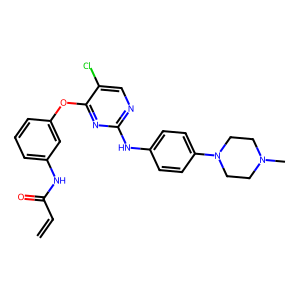

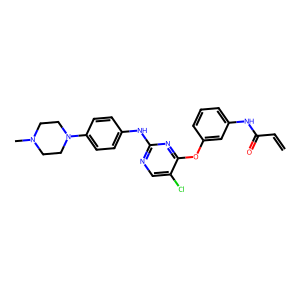


gemma-4-31B     Q4    7/375 1.87%
gpt-oss-120B    BF16  0/344 0.00%
prompt = O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCCC4)=NC=C2C)=C1)(NC(C)(C)C)=O
model  =  Cc1cnc(Nc2ccc(OCCN3CCCC3)cc2)nc1Nc1cccc(S(=O)(=O)NC(C)(C)C)c1


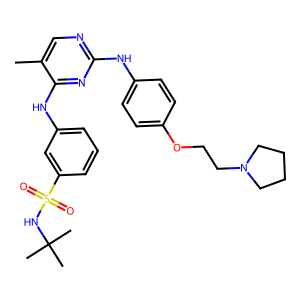

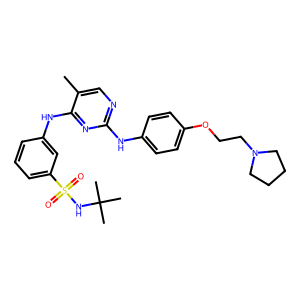


prompt = O=C(NC1=CC=C(C=C1F)OC2=CC(NC(N3CCC(CC3)N4CCN(CC4)C)=O)=NC=C2)C5(CC5)C(NC6=CC=C(C=C6)F)=O
model  =  CN1CCN(C2CCN(C(=O)Nc3cc(Oc4ccc(NC(=O)C5(C(=O)Nc6ccc(F)cc6)CC5)c(F)c4)ccn3)CC2)CC1


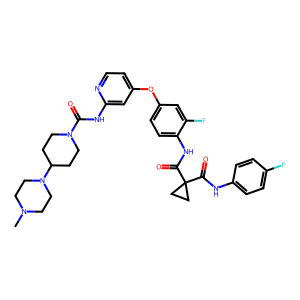

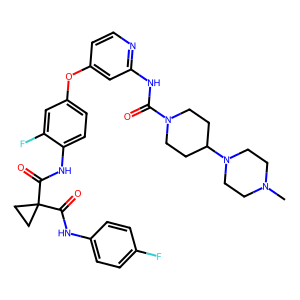


gpt-oss-120B    Q8    2/342 0.58%
prompt = NC1=C2C(N(C=C2C3=CC=CC(OCC4=CC=CC=C4)=C3)[C@H]5C[C@@H](C5)CN6CCCC6)=NC=N1
model  =  Nc1ncnc2c1c(-c1cccc(OCc3ccccc3)c1)cn2[C@H]1C[C@H](CN2CCCC2)C1


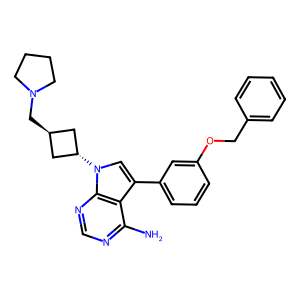

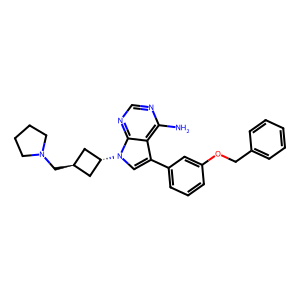


prompt = O=C1NC2=CC(C(OC)=O)=CC=C2/C1=C(NC3=CC=C(N(C(CN4CCN(C)CC4)=O)C)C=C3)\\C5=CC=CC=C5
model  =  COC(=O)c1ccc2c(c1)NC(=O)/C2=C(\Nc1ccc(N(C)C(=O)CN2CCN(C)CC2)cc1)c1ccccc1


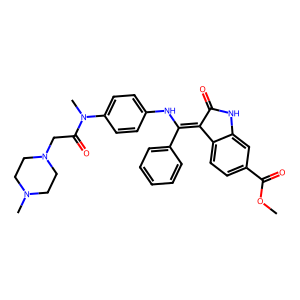

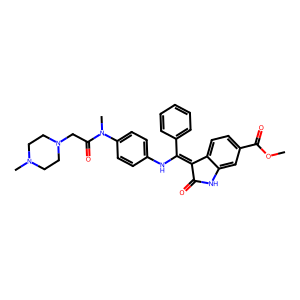


prompt = O=C(NC1=CN2C(C(NC3=CC4=C(N(CC5=CC=CC(F)=C5)N=C4)C=C3)=NC=N2)=C1C)OC[C@H]6NCCOC6
model  =  Cc1c(NC(=O)OC[C@@H]2COCCN2)cn2ncnc(Nc3ccc4c(cnn4Cc4cccc(F)c4)c3)c12


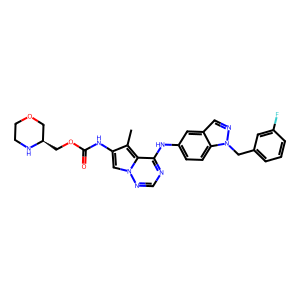

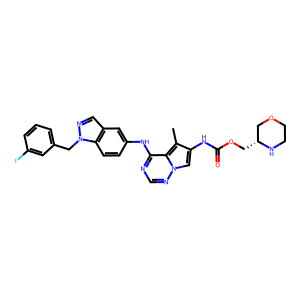


prompt = C[C@H](C1=CC=CC=C1)NC2=C(C=C3C(C=C4)=CC=C4CN5CCN(CC)CC5)C(N3)=NC=N2
model  =  CCN1CCN(Cc2ccc(-c3cc4c(N[C@H](C)c5ccccc5)ncnc4[nH]3)cc2)CC1


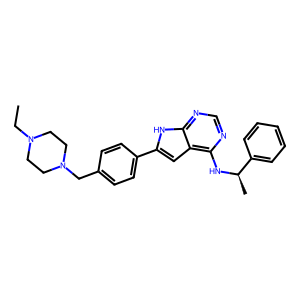

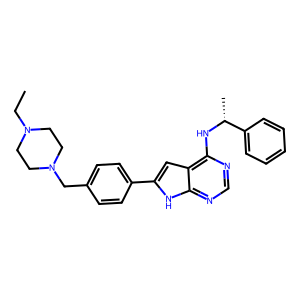


prompt = COC1=CC2=NC=NC(NC3=CC=CC(Cl)=C3)=C2C=C1OC
model  =  COc1cc2ncnc(Nc3cccc(Cl)c3)c2cc1OC


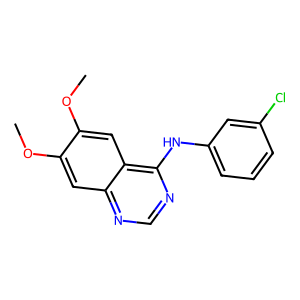

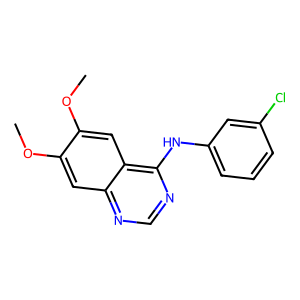


prompt = O=C(C1=C(C)N(CC(C)(O)C)N(C2=CC=CC=C2)C1=O)NC3=NC=C(OC4=CC=NC5=CC(OC)=CC=C45)C=C3
model  =  COc1ccc2c(Oc3ccc(NC(=O)c4c(C)n(CC(C)(C)O)n(-c5ccccc5)c4=O)nc3)ccnc2c1


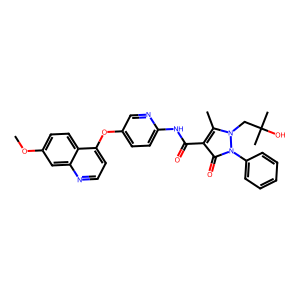

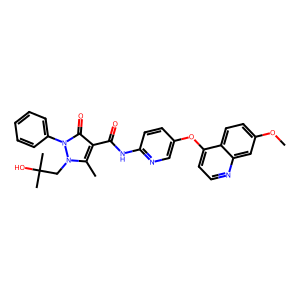


prompt = O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)N4CCN(CC4)C)=NC=C2C)=C1)(NC(C)(C)C)=O
model  =  Cc1cnc(Nc2ccc(N3CCN(C)CC3)cc2)nc1Nc1cccc(S(=O)(=O)NC(C)(C)C)c1


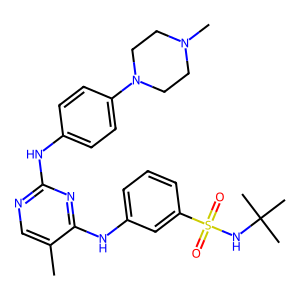

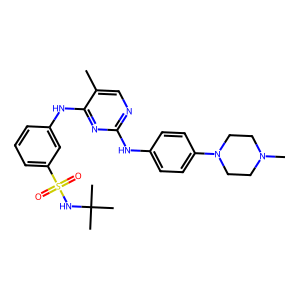


prompt = CN1CCN(C2=CC=C(C=C2)NC3=NC=C(C(OC4=CC(NC(C=C)=O)=CC=C4)=N3)Cl)CC1
model  =  C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(C)CC4)cc3)ncc2Cl)c1


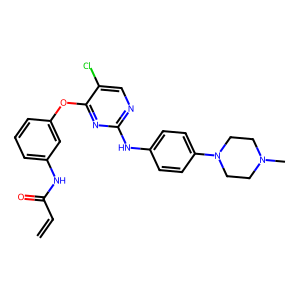

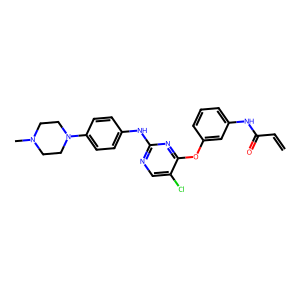


prompt = O=C(/C=C/CN1CCCCC1)NC2=CC3=C(C=C2OC)N=CN=C3NC4=CC=C(C(Cl)=C4)F
model  =  COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)/C=C/CN1CCCCCC1


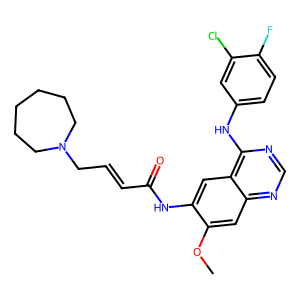

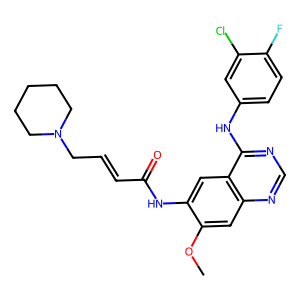


prompt = CN1CCN(C2=CC=C(C=C2)NC3=NC=C(C(OC4=CC(NC(C=C)=O)=CC=C4)=N3)Cl)CC1
model  =  C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(C)CC4)cc3)ncc2Cl)c1


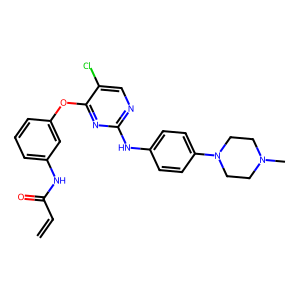

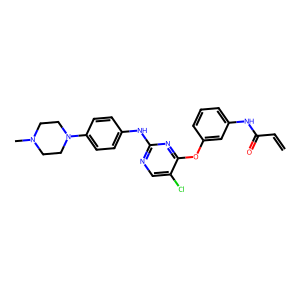


prompt = CN1CCN(C2=CC=C(C=C2)NC3=NC=C(C(OC4=CC(NC(C=C)=O)=CC=C4)=N3)Cl)CC1
model  =  C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(C)CC4)cc3)ncc2Cl)c1


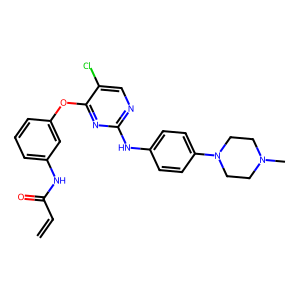

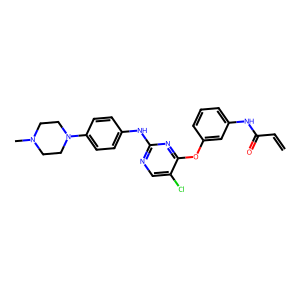


prompt = O=C(NC1=C(C=C2C(C(NC3=CC=C(C(Cl)=C3)F)=NC=N2)=C1)OCCCN4CCOCC4)C=C
model  =  C=CC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OCCCN1CCOCC1


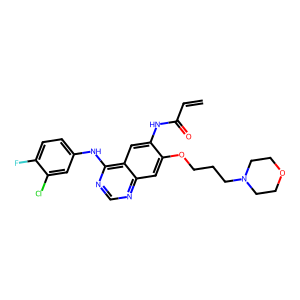

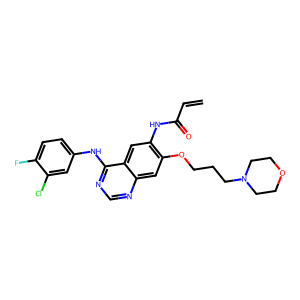


prompt = CN1CCN(C2=CC=C(C=C2)NC3=NC=C(C(OC4=CC(NC(C=C)=O)=CC=C4)=N3)Cl)CC1
model  =  C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(C)CC4)cc3)ncc2Cl)c1


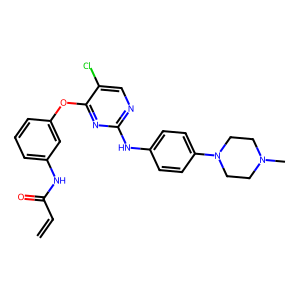

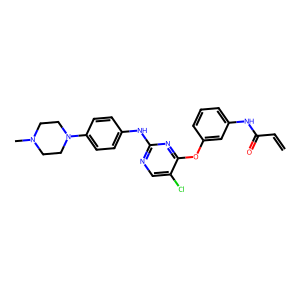


gpt-oss-120B    Q6    13/360 3.61%
gpt-oss-120B    Q4    0/325 0.00%

61


In [58]:
lst_smi_prompt = d_smiles['prompt']
lst_mol_prompt = [Chem.MolFromSmiles(smi) for smi in lst_smi_prompt]
lst_fps_prompt = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol_prompt]
total_prompt = len(lst_smi_prompt)

for m in lst_models:
    for q in lst_quants:
        n_eq = 0
        
        lst_smi = d_smiles[m][q]        
        lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
        lst_fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]
        total = len(lst_smi)

        for i1,m1 in enumerate(lst_fps):
                lst_sim = []
                for i2,m2 in enumerate(lst_fps_prompt):
                    sim = DataStructs.TanimotoSimilarity(m1, m2)
                    if sim == 1.0:
                         print('prompt =', lst_smi_prompt[i2])
                         print('model  = ', lst_smi[i1])
                         
                         display(Draw.MolToImage(lst_mol[i1]))
                         display(Draw.MolToImage(lst_mol_prompt[i2]))
                         
                         print()
                         n_eq+=1
        pct_eq = (n_eq/total)*100
        print(f'{m:15s} {q:5s} {n_eq}/{total} {pct_eq:.2f}%')

print()
print(n)

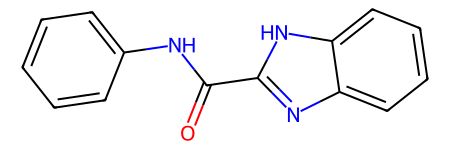